# HotelRec: Scientific Model Comparison and BERT Extension

This notebook focuses on *evaluation and scientific analysis* of multiple recommendation models
for the HotelRec dataset. We compare:

1. **Popularity baseline**  
   - Items ranked by rating count or Bayesian mean
2. **Raw TF‑IDF content-based model**  
   - Direct TF‑IDF on review text, minimal preprocessing
3. **Enhanced TF‑IDF content-based model**  
   - Stemming, n‑grams, smarter stopword handling (as in the first notebook)
4. **BERT-based content model (Sentence Embeddings)**  
   - Uses a pretrained transformer encoder to represent hotel review text

The goal is to answer:

- How much does content-based modeling improve over a pure popularity baseline?
- How much gain do we get from advanced text preprocessing (enhanced TF‑IDF) vs raw TF‑IDF?
- Does a BERT-based model outperform TF‑IDF for this task under the same evaluation protocol?

We use a **per-user holdout** and report:

- HitRate@K  
- Precision@K  
- Recall@K  
- F1@K  
- NDCG@K  

for several values of K.


## 1. Imports and Configuration


In [1]:
import os, glob, ast, time, math
import pandas as pd
import numpy as np
import scipy.sparse as sp
from typing import Optional, Dict, List, Tuple
#
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize as sk_normalize
#
# Optional, but nice for progress bars
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **kwargs):
        return x
#
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
#

## 2. Data Loading

We reuse the filtered CSV shards you already created.  
The logic is:

- Search for `*.csv` in `DATA_PATH` and a few reasonable relatives  
- Concatenate shards  
- Enforce `MIN_USER` and `MIN_ITEM` constraints  
- Cast user/item to string, rating to float32


In [2]:
# %% [markdown]
# ## 2. Data Loading (clean external CSV)

# %%
import os, glob
import numpy as np
import pandas as pd

# CHANGED: project root is now only a fallback for relative paths
PROJECT_ROOT = os.path.abspath(
    os.path.join(
        os.path.dirname(__file__) if "__file__" in globals() else os.getcwd(),
        ".",
        ".",
    )
)

# CHANGED: point directly to your cleaned dense CSV outside the repo
DATA_PATH = r"F:\Files\Coding\recsys-Yann-individual\recsys-Yann-individual\data\hotelrec_dense_k20_Yann.csv"

LIMIT_PER_FILE = None               # or set to an int to debug on a subset
MIN_USER = 3
MIN_ITEM = 3

paths: list[str] = []

# Case 1: DATA_PATH is a single CSV file
if os.path.isfile(DATA_PATH) and DATA_PATH.lower().endswith(".csv"):
    paths = [DATA_PATH]
    print(f"Using single CSV file: {DATA_PATH}")

# Case 2: DATA_PATH is a directory containing many CSVs
elif os.path.isdir(DATA_PATH):
    paths = sorted(glob.glob(os.path.join(DATA_PATH, "*.csv")))
    print(f"Using data directory: {DATA_PATH}")

# Case 3: relative path or something else → try resolving under PROJECT_ROOT/data*
else:
    candidate_dirs = [
        os.path.join(PROJECT_ROOT, DATA_PATH),
        os.path.join(PROJECT_ROOT, "data", "filtered"),
        os.path.join(PROJECT_ROOT, "data"),
    ]
    for base in candidate_dirs:
        if os.path.isdir(base):
            shard_paths = sorted(glob.glob(os.path.join(base, "*.csv")))
            if shard_paths:
                paths = shard_paths
                DATA_PATH = base
                print(f"Using data directory: {DATA_PATH}")
                break

if not paths:
    raise FileNotFoundError(
        "Could not find any CSV files.\n"
        f"  Checked file/dir: {DATA_PATH}\n"
        "  And some candidate directories under project root.\n"
        "Please adjust DATA_PATH."
    )

print(f"Found {len(paths)} CSV shard(s).")

dfs = []
for p in paths:
    print("Reading", os.path.basename(p))
    df = pd.read_csv(p)
    if LIMIT_PER_FILE is not None:
        df = df.head(LIMIT_PER_FILE)
    dfs.append(df)

ratings = pd.concat(dfs, ignore_index=True)

# Basic typing & filtering
print("Columns in loaded CSV:", ratings.columns.tolist())

# Try to guess column names
user_candidates   = ["user", "user_id", "userid", "userId", "reviewer", "customer_id"]
item_candidates   = ["item", "item_id", "itemid", "itemId", "hotel_id", "sid", "s_id"]
rating_candidates = ["rating", "score", "stars", "overall", "rating_val"]

def pick_col(candidates, what):
    for c in candidates:
        if c in ratings.columns:
            print(f"Using column '{c}' as {what}")
            return c
    raise KeyError(
        f"Could not find a column for {what}. "
        f"Tried: {candidates}. "
        f"Available columns: {ratings.columns.tolist()}"
    )

user_col   = pick_col(user_candidates,   "user")
item_col   = pick_col(item_candidates,   "item")
rating_col = pick_col(rating_candidates, "rating")

# Rename to canonical names
ratings = ratings.rename(
    columns={
        user_col: "user",
        item_col: "item",
        rating_col: "rating",
    }
)
ratings["user"] = ratings["user"].astype(str)
ratings["item"] = ratings["item"].astype(str)
ratings["rating"] = ratings["rating"].astype(np.float32)

# Apply min-count filtering
user_counts = ratings["user"].value_counts()
item_counts = ratings["item"].value_counts()
ratings = ratings[
    ratings["user"].isin(user_counts.index[user_counts >= MIN_USER])
    & ratings["item"].isin(item_counts.index[item_counts >= MIN_ITEM])
].reset_index(drop=True)

print(f"Loaded ratings: {len(ratings):,} rows")
print(f"Users: {ratings['user'].nunique():,}, Items: {ratings['item'].nunique():,}")
print("Rating distribution:")
print(ratings["rating"].value_counts().sort_index())


Using single CSV file: F:\Files\Coding\recsys-Yann-individual\recsys-Yann-individual\data\hotelrec_dense_k20_Yann.csv
Found 1 CSV shard(s).
Reading hotelrec_dense_k20_Yann.csv
Columns in loaded CSV: ['user_id', 'item_id', 'rating', 'sleep quality', 'value', 'rooms', 'service', 'cleanliness', 'location', 'text']
Using column 'user_id' as user
Using column 'item_id' as item
Using column 'rating' as rating
Loaded ratings: 1,400,102 rows
Users: 46,660, Items: 27,197
Rating distribution:
rating
1.0     19152
2.0     58234
3.0    247089
4.0    580740
5.0    494887
Name: count, dtype: int64


## 3. Experiment Protocol

### 3.1 Per-User Holdout

For each user \( u \) with at least two interactions:

- Randomly select \( \max(1, \lfloor 0.2 \cdot |I_u| 
floor) \) items for the **test set**
- Use the remaining items for the **training set**

where \( I_u \) is the set of items user \( u \) interacted with.

This yields:

- `train_df`: interactions used for learning models  
- `test_dict`: mapping `user -> set(test_items)` used for evaluation only  

The split is stratified by user, so every user with enough interactions contributes test data.


In [3]:
def make_per_user_holdout(ratings: pd.DataFrame, test_frac: float = 0.2, seed: int = 42):
    rng = np.random.default_rng(seed)
    df = ratings.sample(frac=1.0, random_state=seed)
    groups = df.groupby("user", observed=False)
#
    train_parts = []
    test_dict: Dict[str, set] = {}
#
    for u, g in groups:
        n = len(g)
        if n <= 1:
            train_parts.append(g)
            continue
        m = max(1, int(round(n * test_frac)))
        idx = rng.choice(g.index.to_numpy(), size=m, replace=False)
        test_items = set(g.loc[idx, "item"].astype(str).tolist())
        train_parts.append(g.drop(index=idx))
        test_dict[u] = test_items
#
    train_df = pd.concat(train_parts, ignore_index=True)
    return train_df, test_dict
#
train_df, test_dict = make_per_user_holdout(ratings, test_frac=0.2, seed=RANDOM_SEED)
#
print(f"Train interactions: {len(train_df):,}")
print(f"Users with test data: {len(test_dict):,}")
#

Train interactions: 1,121,187
Users with test data: 46,660


## 4. Core Interfaces and Utilities

We reuse the same basic interface as in your first notebook:  

- `BaseAlgo` with `fit` and `predict_for_user`  
- `RecEngine` wrapper that:
  - holds a primary model
  - optional fallback (for cold-start users)
  - handles filtering already-seen items


In [5]:
class BaseAlgo:
    def fit(self, ratings: pd.DataFrame):
        raise NotImplementedError
#
    def predict_for_user(self, user, candidates=None, n: int = 10) -> pd.DataFrame:
        raise NotImplementedError
#
    def recommend(self, user, n: int = 10, candidates=None) -> pd.DataFrame:
        res = self.predict_for_user(user, candidates=candidates, n=n)
        return res.head(n) if isinstance(res, pd.DataFrame) else res
#
def build_user_hist(ratings: pd.DataFrame) -> Dict[str, set]:
    return ratings.groupby("user", observed=False)["item"].apply(set).to_dict()
#
def filter_seen(recs: pd.DataFrame, seen_items: set):
    if recs is None or recs.empty:
        return recs
    return recs[~recs["item"].isin(seen_items)].reset_index(drop=True)
#
class RecEngine:
    def __init__(self, algo: BaseAlgo, fallback: Optional[BaseAlgo] = None):
        self.algo = algo
        self.fallback = fallback
        self.user_hist: Dict[str, set] = {}
#
    def fit(self, ratings: pd.DataFrame):
        self.user_hist = build_user_hist(ratings)
        self.algo.fit(ratings)
        if self.fallback is not None:
            self.fallback.fit(ratings)
        return self
#
    def recommend(self, user, n: int = 10, candidates=None, filter_seen_items: bool = True) -> pd.DataFrame:
        is_cold = user not in self.user_hist or len(self.user_hist.get(user, ())) == 0
        model = self.fallback if (is_cold and self.fallback is not None) else self.algo
        recs = model.recommend(user, n=n, candidates=candidates)
        if filter_seen_items and user in self.user_hist and recs is not None and not recs.empty:
            recs = filter_seen(recs, self.user_hist[user])
        return recs.head(n) if recs is not None else recs
#

## 5. Models

We define four model families used in this notebook:

1. `PopularityAlgo` (baseline)  
2. `RawTFIDFContentAlgo` (raw TF‑IDF, no heavy preprocessing)  
3. `EnhancedContentBasedAlgo` (similar to your improved version)  
4. `BertContentBasedAlgo` (SentenceTransformer embeddings)

The content models all share the same high-level idea:

- Build an **item vector** \( v_i \) for each hotel \( i \)  
- For each user \( u \), find items that were liked (rating above a threshold)  
- Build a **user profile** vector \( p_u \) as a weighted average of liked item vectors  
- Score candidate items by cosine similarity \( s(u, i) = \cos(p_u, v_i) \)  
- Use this as the ranking score


### 5.1 Popularity Baseline


# Baseline Models: Random and Popularity

In [6]:
class RandomAlgo(BaseAlgo):
    """Simple random recommender used as an additional baseline."""
    def __init__(self, seed: int = 42):
        self.seed = seed
        self.rng = np.random.default_rng(seed)
        self.items_: List[str] = []

    def fit(self, ratings: pd.DataFrame):
        # Store all items seen in the training data
        self.items_ = sorted(ratings["item"].astype(str).unique())
        return self

    def predict_for_user(self, user, candidates=None, n: int = 10) -> pd.DataFrame:
        if not self.items_:
            raise RuntimeError("RandomAlgo must be fitted before prediction.")

        if candidates is not None:
            pool = [str(it) for it in candidates]
        else:
            pool = self.items_

        if not pool:
            return pd.DataFrame(columns=["item", "score"])

        n_sample = min(n, len(pool))
        # Sample without replacement and assign random scores so the ranking is random
        idx = self.rng.choice(len(pool), size=n_sample, replace=False)
        chosen = [pool[i] for i in idx]
        scores = self.rng.random(n_sample)

        out = pd.DataFrame({"item": chosen, "score": scores}).sort_values(
            "score", ascending=False
        )
        return out.reset_index(drop=True)


class PopularityAlgo(BaseAlgo):
    def __init__(self, mode: str = "count", min_count: int = 1):
        """
        mode:
          - 'count': sort by number of ratings
          - 'mean' : sort by average rating
        """
        self.mode = mode
        self.min_count = min_count
        self.item_scores_ = None

    def fit(self, ratings: pd.DataFrame):
        grp = ratings.groupby("item")["rating"]
        counts = grp.size().rename("count")
        means = grp.mean().rename("mean")

        items = pd.concat([counts, means], axis=1).reset_index()

        if self.mode == "count":
            items["score"] = items["count"]
        elif self.mode == "mean":
            items["score"] = items["mean"]
        else:
            raise ValueError(f"Unknown mode: {self.mode}")

        if self.min_count and self.min_count > 1:
            items = items[items["count"] >= self.min_count]

        self.item_scores_ = items[["item", "score"]].sort_values(
            "score", ascending=False
        ).reset_index(drop=True)
        return self

    def predict_for_user(self, user, candidates=None, n: int = 10) -> pd.DataFrame:
        if self.item_scores_ is None:
            raise RuntimeError("PopularityAlgo must be fitted before prediction.")
        df = self.item_scores_
        if candidates is not None:
            cand_set = set(candidates)
            df = df[df["item"].isin(cand_set)]
        return df.head(n).copy()


### 5.2 Raw TF‑IDF Content-Based Model

This model is deliberately simple:

- Use the `text` column as is (only basic cleaning)  
- Apply `TfidfVectorizer` with unigrams  
- Build user profiles and score by cosine similarity


In [15]:
import torch
import numpy as np
import pandas as pd
import scipy.sparse as sp
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize as sk_normalize
from typing import List, Dict, Tuple, Optional

# Assuming BaseAlgo is already defined in your notebook
class RawTFIDFContentAlgo(BaseAlgo):
    def __init__(
        self,
        min_df: int = 5,
        max_features: int = 50000,
        like_threshold: float = 3.5,
        device: str = 'cuda' if torch.cuda.is_available() else 'cpu'
    ):
        self.min_df = min_df
        self.max_features = max_features
        self.like_threshold = like_threshold
        self.device = device

        self.vectorizer_ = None
        # Keep CPU matrix for fast slicing of user profiles
        self.item_matrix_cpu_ = None
        # Keep GPU tensor for fast global scoring
        self.item_matrix_gpu_ = None

        self.items_: List[str] = []
        self.item_index_: Dict[str, int] = {}
        self.user_items_: Dict[str, List[Tuple[str, float]]] = {}

    def _build_item_texts(self, ratings: pd.DataFrame) -> pd.Series:
        if "text" not in ratings.columns:
            return pd.Series(dtype=str)
        tmp = ratings[["item", "text"]].copy()
        tmp["text"] = tmp["text"].fillna("").astype(str)
        tmp = tmp[tmp["text"].str.strip() != ""]
        return tmp.groupby("item", observed=False)["text"].apply(lambda x: " ".join(x))

    def fit(self, ratings: pd.DataFrame):
        # 1. CPU: Build Text & Vectorize
        item_texts = self._build_item_texts(ratings)
        print(f"[RawTFIDF-GPU] Items with text: {len(item_texts)}")

        self.items_ = sorted(list(set(ratings["item"].astype(str).unique())))
        self.item_index_ = {it: idx for idx, it in enumerate(self.items_)}

        texts = [item_texts.get(it, "") for it in self.items_]

        self.vectorizer_ = TfidfVectorizer(
            min_df=self.min_df, max_features=self.max_features
        )
        # X_text is a Scipy CSR matrix (CPU)
        X_text = self.vectorizer_.fit_transform(texts)
        self.item_matrix_cpu_ = X_text

        # 2. GPU: Convert to PyTorch Sparse Tensor
        print(f"[RawTFIDF-GPU] Moving matrix {X_text.shape} to {self.device}...")
        coo = X_text.tocoo()
        indices = torch.from_numpy(np.vstack((coo.row, coo.col))).long()
        values = torch.from_numpy(coo.data).float()

        if self.device == 'cuda':
            # Create directly on GPU
            self.item_matrix_gpu_ = torch.sparse_coo_tensor(
                indices, values, size=coo.shape, device=self.device
            ).coalesce()
        else:
            self.item_matrix_gpu_ = torch.sparse_coo_tensor(
                indices, values, size=coo.shape
            )

        # 3. User History
        interactions = ratings[["user", "item", "rating"]].dropna()
        interactions["item"] = interactions["item"].astype(str)
        interactions["rating"] = interactions["rating"].astype(float)

        self.user_items_ = (
            interactions.groupby("user", observed=False)
            .apply(lambda g: list(zip(g["item"].tolist(), g["rating"].tolist())))
            .to_dict()
        )
        return self

    def _user_profile(self, user: str) -> Optional[torch.Tensor]:
        """Builds the user profile on CPU, then moves to GPU."""
        if user not in self.user_items_:
            return None

        liked_idxs = []
        weights = []
        for it, r in self.user_items_[user]:
            w = max(0.0, float(r) - float(self.like_threshold))
            if w <= 0.0: continue
            idx = self.item_index_.get(it)
            if idx is None: continue
            liked_idxs.append(idx)
            weights.append(w)

        if not liked_idxs:
            return None

        # Slicing is faster on CPU using Scipy
        sub_matrix = self.item_matrix_cpu_[liked_idxs, :]
        w_array = np.array(weights, dtype=np.float32).reshape(1, -1)

        # Profile calculation (small dense vector, CPU is fine here)
        prof = w_array @ sub_matrix
        prof = sk_normalize(prof, norm="l2", copy=False)

        # Move final profile vector to GPU
        prof_tensor = torch.from_numpy(prof.astype(np.float32)).to(self.device)
        return prof_tensor.view(-1) # Flatten to 1D

    def predict_for_user(self, user, candidates=None, n: int = 10) -> pd.DataFrame:
        if self.item_matrix_gpu_ is None:
            raise RuntimeError("Fit model first.")

        # 1. Get User Profile (Tensor on GPU)
        prof_vec = self._user_profile(user)
        if prof_vec is None:
            return pd.DataFrame(columns=["item", "score"])

        # 2. Calculate Scores (Matrix Multiplication on GPU)
        # Sparse Matrix (Items, Feat) @ Dense Vector (Feat) -> Dense Vector (Items)
        all_scores = torch.mv(self.item_matrix_gpu_, prof_vec)

        # 3. Filter / Top-K
        if candidates is None:
            # Global Top-K on GPU
            k_val = min(n, len(self.items_))
            topk = torch.topk(all_scores, k=k_val)

            indices = topk.indices.cpu().numpy()
            vals = topk.values.cpu().numpy()

            items = [self.items_[i] for i in indices]
            return pd.DataFrame({"item": items, "score": vals})
        else:
            # Filter specific candidates
            cand_idx = [self.item_index_.get(it) for it in candidates]
            cand_pairs = [(i, it) for i, it in zip(cand_idx, candidates) if i is not None]

            if not cand_pairs:
                return pd.DataFrame(columns=["item", "score"])

            target_indices = [i for i, _ in cand_pairs]
            target_items = [it for _, it in cand_pairs]

            # Select scores from the GPU tensor
            idx_tensor = torch.tensor(target_indices, device=self.device)
            cand_scores = torch.index_select(all_scores, 0, idx_tensor)

            scores_np = cand_scores.cpu().numpy()

            return pd.DataFrame({"item": target_items, "score": scores_np}).sort_values(
                "score", ascending=False
            ).head(n).reset_index(drop=True)

### 5.3 Enhanced TF‑IDF Content-Based Model

This is essentially your improved version:

- Advanced preprocessing (lowercasing, cleaning)  
- NLTK stopwords with negations kept  
- Stemming (optional)  
- N‑grams (unigram + bigram by default)  

We focus on text only here to keep the comparison clean.


In [29]:
import re
import numpy as np
import pandas as pd
import scipy.sparse as sp
import torch
from typing import List, Dict, Tuple, Optional
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import normalize as sk_normalize
from joblib import Parallel, delayed

# NLTK Imports
try:
    import nltk
    from nltk.stem import PorterStemmer
    from nltk.corpus import stopwords
    _ = stopwords.words("english")
except LookupError:
    import nltk
    nltk.download("stopwords", quiet=True)
    from nltk.corpus import stopwords
    from nltk.stem import PorterStemmer

# --- STANDALONE WORKER FUNCTION (Fixes PicklingError) ---
def _preprocess_text_worker(text: str, stop_words: set, use_stemming: bool) -> str:
    """
    Standalone function to avoid pickling the entire class instance.
    """
    if pd.isna(text) or not text:
        return ""

    text = str(text).lower()
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()

    if not text:
        return ""

    tokens = text.split()
    processed = []

    # Initialize stemmer locally if needed
    stemmer = PorterStemmer() if use_stemming else None

    for tok in tokens:
        if len(tok) >= 2 and tok not in stop_words:
            if stemmer:
                processed.append(stemmer.stem(tok))
            else:
                processed.append(tok)

    return " ".join(processed) if processed else text


# --- OPTIMIZED CLASS ---

class EnhancedContentBasedAlgo(BaseAlgo):
    def __init__(
        self,
        min_df: int = 3,
        max_df: float = 0.7,
        max_features: int = 50_000,
        ngram_range: tuple = (1, 2),
        use_stemming: bool = True,
        like_threshold: float = 3.5,
        device: str = "cuda" if torch.cuda.is_available() else "cpu",
        n_jobs: int = -1,
        chunk_size: int = 10_000
    ):
        self.min_df = min_df
        self.max_df = max_df
        self.max_features = max_features
        self.ngram_range = ngram_range
        self.use_stemming = use_stemming
        self.like_threshold = like_threshold
        self.device = device
        self.n_jobs = n_jobs
        self.chunk_size = chunk_size

        self.vectorizer_ = None
        self.gpu_chunks_ = []
        self.item_matrix_cpu_ = None

        self.items_: List[str] = []
        self.item_index_: Dict[str, int] = {}
        self.user_items_: Dict[str, List[Tuple[str, float]]] = {}

        self.stop_words = {"the", "a", "an", "and", "or", "in", "on", "at", "to", "for"}

    def fit(self, ratings: pd.DataFrame):
        print("[EnhancedBatchedGPU] Aggregating item texts...")
        if "text" not in ratings.columns: raise ValueError("Dataset missing 'text' column")

        # 1. Prepare Text
        df_clean = ratings.dropna(subset=["text"])
        df_clean = df_clean[df_clean["text"].str.strip() != ""]
        item_texts_series = df_clean.groupby("item", observed=False)["text"].apply(lambda x: " ".join(x))

        self.items_ = sorted(item_texts_series.index.tolist())
        self.item_index_ = {it: idx for idx, it in enumerate(self.items_)}

        raw_texts = [item_texts_series.get(it, "") for it in self.items_]
        del item_texts_series, df_clean
        gc.collect()

        # 2. Parallel Preprocessing
        print(f"[EnhancedBatchedGPU] Preprocessing {len(raw_texts)} texts...")
        clean_texts = Parallel(n_jobs=self.n_jobs)(
            delayed(_preprocess_text_worker)(t, self.stop_words, self.use_stemming) for t in raw_texts
        )
        del raw_texts
        gc.collect()

        # 3. Vectorization
        print(f"[EnhancedBatchedGPU] Vectorizing...")
        self.vectorizer_ = TfidfVectorizer(
            min_df=self.min_df, max_df=self.max_df, max_features=self.max_features,
            ngram_range=self.ngram_range, strip_accents="unicode", lowercase=True, stop_words=None
        )

        try:
            X_text = self.vectorizer_.fit_transform(clean_texts)
        except ValueError:
            self.vectorizer_.set_params(min_df=1, max_df=1.0, ngram_range=(1,1))
            X_text = self.vectorizer_.fit_transform(clean_texts)

        del clean_texts
        gc.collect()

        self.item_matrix_cpu_ = X_text

        # 4. Batched Move to GPU
        print(f"[EnhancedBatchedGPU] Splitting matrix {X_text.shape} into chunks...")
        self.gpu_chunks_ = []
        n_rows = X_text.shape[0]

        torch.cuda.empty_cache()
        gc.collect()

        for start_idx in range(0, n_rows, self.chunk_size):
            end_idx = min(start_idx + self.chunk_size, n_rows)
            sub_matrix = X_text[start_idx:end_idx]

            # Efficient Sparse Conversion
            coo = sub_matrix.tocoo()
            row_t = torch.from_numpy(coo.row.astype(np.int64))
            col_t = torch.from_numpy(coo.col.astype(np.int64))
            values = torch.from_numpy(coo.data.astype(np.float32))
            indices = torch.stack([row_t, col_t])

            if self.device == "cuda":
                indices = indices.to(self.device)
                values = values.to(self.device)
                chunk = torch.sparse_coo_tensor(
                    indices, values, size=sub_matrix.shape, device=self.device
                ).coalesce()
            else:
                chunk = torch.sparse_coo_tensor(indices, values, size=sub_matrix.shape)

            self.gpu_chunks_.append(chunk)

        print(f"[EnhancedBatchedGPU] Created {len(self.gpu_chunks_)} GPU chunks.")

        # 5. User History
        interactions = ratings[["user", "item", "rating"]].dropna()
        self.user_items_ = (
            interactions.groupby("user", observed=False)
            .apply(lambda g: list(zip(g["item"], g["rating"])))
            .to_dict()
        )
        return self

    def _user_profile(self, user: str) -> Optional[torch.Tensor]:
        if user not in self.user_items_: return None

        liked_idxs = []
        weights = []
        for it, r in self.user_items_[user]:
            w = max(0.0, float(r) - self.like_threshold)
            if w > 0:
                idx = self.item_index_.get(str(it))
                if idx is not None:
                    liked_idxs.append(idx)
                    weights.append(w)

        if not liked_idxs: return None

        # Slice CPU matrix
        user_sub_matrix = self.item_matrix_cpu_[liked_idxs, :]
        w_array = np.array(weights, dtype=np.float32).reshape(1, -1)

        # Dense @ Sparse = Dense array
        profile_vec = w_array @ user_sub_matrix
        profile_vec = sk_normalize(profile_vec, norm='l2')

        # FIX: Handle both sparse and dense cases
        if sp.issparse(profile_vec):
            profile_vec = profile_vec.toarray()

        # Move to GPU
        profile_tensor = torch.from_numpy(profile_vec).float()
        if self.device == "cuda":
            return profile_tensor.to(self.device).squeeze(0)
        return profile_tensor.squeeze(0)

    def predict_for_user(self, user, candidates=None, n: int = 10) -> pd.DataFrame:
        if not self.gpu_chunks_: raise RuntimeError("Fit first.")
        prof_vec = self._user_profile(user)
        if prof_vec is None: return pd.DataFrame(columns=["item", "score"])

        # Calculate scores in batches
        all_scores_list = []

        for chunk in self.gpu_chunks_:
            batch_scores = torch.mv(chunk, prof_vec)
            all_scores_list.append(batch_scores)

        all_scores = torch.cat(all_scores_list)

        if candidates is not None:
            cand_indices = [self.item_index_.get(str(c)) for c in candidates]
            valid_pairs = [(i, c) for i, c in zip(cand_indices, candidates) if i is not None]
            if not valid_pairs: return pd.DataFrame(columns=["item", "score"])

            target_indices = [p[0] for p in valid_pairs]
            target_items = [p[1] for p in valid_pairs]

            idx_tensor = torch.tensor(target_indices, device=self.device)
            cand_scores = torch.index_select(all_scores, 0, idx_tensor)

            return pd.DataFrame({
                "item": target_items, "score": cand_scores.cpu().numpy()
            }).sort_values("score", ascending=False).head(n).reset_index(drop=True)
        else:
            k_val = min(n, len(self.items_))
            topk = torch.topk(all_scores, k_val)
            return pd.DataFrame({
                "item": [self.items_[i] for i in topk.indices.cpu().numpy()],
                "score": topk.values.cpu().numpy()
            })

### 5.4 BERT-Based Content Model (Sentence Embeddings)

We now add a BERT-style encoder.  
We use `sentence-transformers` so that each hotel's reviews are encoded into a dense vector:

\[
v_i = 	ext{SentenceTransformer}(	ext{concat\_reviews}_i)
\]

The user profile is again a weighted average of liked items:

\[
p_u = 
rac{\sum_{i \in L_u} w_{u, i} v_i}{\sqrt{\sum_{j} \left(\sum_{i \in L_u} w_{u,i} v_{i,j}
ight)^2}}
\]

where \( L_u \) is the set of liked items for user \( u \).

Scoring is cosine similarity between \( p_u \) and each candidate \( v_i \).


In [9]:
import torch
import numpy as np
import pandas as pd
from typing import Optional, List, Dict, Tuple

try:
    from sentence_transformers import SentenceTransformer
except ImportError:
    SentenceTransformer = None

class BertContentBasedAlgo(BaseAlgo):
    def __init__(
        self,
        model_name: str = "sentence-transformers/all-MiniLM-L6-v2",
        batch_size: int = 64,  # RTX 3070 Ti can likely handle 128
        like_threshold: float = 3.5,
        device: Optional[str] = None,
    ):
        if SentenceTransformer is None:
            raise ImportError("pip install sentence-transformers")

        self.model_name = model_name
        self.batch_size = batch_size
        self.like_threshold = like_threshold
        # Auto-detect GPU if not specified
        self.device = device if device else ("cuda" if torch.cuda.is_available() else "cpu")

        self.model: Optional[SentenceTransformer] = None
        # Store as Tensor instead of np.ndarray
        self.item_embeddings_: Optional[torch.Tensor] = None
        self.items_: List[str] = []
        self.item_index_: Dict[str, int] = {}
        self.user_items_: Dict[str, List[Tuple[str, float]]] = {}

    def _build_item_texts(self, ratings: pd.DataFrame) -> pd.Series:
        if "text" not in ratings.columns:
            return pd.Series(dtype=str)
        tmp = ratings[["item", "text"]].copy()
        tmp["text"] = tmp["text"].fillna("").astype(str)
        tmp = tmp[tmp["text"].str.strip() != ""]
        return tmp.groupby("item", observed=False)["text"].apply(lambda x: " ".join(x))

    def fit(self, ratings: pd.DataFrame):
        print(f"[BERT] Loading model: {self.model_name} on {self.device}")
        self.model = SentenceTransformer(self.model_name, device=self.device)

        item_texts = self._build_item_texts(ratings)
        print(f"[BERT] Items with text: {len(item_texts)}")

        self.items_ = sorted(list(set(ratings["item"].astype(str).unique())))
        self.item_index_ = {it: idx for idx, it in enumerate(self.items_)}

        texts = [item_texts.get(it, "") for it in self.items_]

        print("[BERT] Encoding item texts (GPU)...")
        # Keep embeddings on GPU as a Tensor
        self.item_embeddings_ = self.model.encode(
            texts,
            batch_size=self.batch_size,
            show_progress_bar=True,
            convert_to_tensor=True,  # Critical for GPU speedup
            normalize_embeddings=True,
            device=self.device
        )

        interactions = ratings[["user", "item", "rating"]].dropna()
        interactions["item"] = interactions["item"].astype(str)
        interactions["rating"] = interactions["rating"].astype(float)

        self.user_items_ = (
            interactions.groupby("user", observed=False)
            .apply(lambda g: list(zip(g["item"].tolist(), g["rating"].tolist())))
            .to_dict()
        )
        print("[BERT] Model trained (embeddings on GPU).")
        return self

    def _user_profile(self, user: str):
        if user not in self.user_items_:
            return None

        liked_idxs = []
        weights = []

        for it, r in self.user_items_[user]:
            w = max(0.0, float(r) - float(self.like_threshold))
            if w <= 0.0: continue
            idx = self.item_index_.get(it)
            if idx is None: continue
            liked_idxs.append(idx)
            weights.append(w)

        if not liked_idxs:
            return None

        # Slice the GPU tensor
        liked_vecs = self.item_embeddings_[liked_idxs]

        # Create weights tensor on GPU
        w_tensor = torch.tensor(weights, device=self.device).view(-1, 1)

        # Weighted sum using torch operations
        prof = (liked_vecs * w_tensor).sum(dim=0)

        # Normalize
        norm = torch.norm(prof)
        if norm < 1e-8:
            return None
        return prof / norm

    def predict_for_user(self, user, candidates=None, n: int = 10) -> pd.DataFrame:
        if self.item_embeddings_ is None:
            raise RuntimeError("Fit model first.")

        prof = self._user_profile(user) # Returns GPU tensor
        if prof is None:
            return pd.DataFrame(columns=["item", "score"])

        # Calculate scores using Torch (GPU)
        if candidates is None:
            # Matrix Mult on GPU
            scores = torch.matmul(self.item_embeddings_, prof)

            # Torch.topk is faster than argsort for large arrays on GPU
            top_k = torch.topk(scores, k=min(n, len(scores)))

            # Move results to CPU only at the end
            vals = top_k.values.cpu().numpy()
            indices = top_k.indices.cpu().numpy()

            items = [self.items_[i] for i in indices]
            return pd.DataFrame({"item": items, "score": vals})

        # Filtering Candidates
        cand_idx = [self.item_index_.get(it) for it in candidates]
        cand_pairs = [(i, it) for i, it in zip(cand_idx, candidates) if i is not None]

        if not cand_pairs:
            return pd.DataFrame(columns=["item", "score"])

        rows = [i for i, _ in cand_pairs]
        # Slice GPU tensor
        emb = self.item_embeddings_[rows]

        # Dot product on GPU
        # Move to CPU immediately after calc since we have to sort via pandas/python list anyway
        scores = torch.matmul(emb, prof).cpu().numpy()
        items = [it for _, it in cand_pairs]

        out = pd.DataFrame({"item": items, "score": scores}).sort_values("score", ascending=False)
        return out.head(n).reset_index(drop=True)

## 6. Evaluation Metrics

For a given user \( u \), let:

- \( T_u \) be the set of test items (held-out items)  
- \( R_u^K \) be the top K recommended items  

Then:

- **HitRate@K**: fraction of users with at least one hit  
  \[
  	ext{HitRate@K} = 
rac{1}{|U|} \sum_{u \in U} \mathbf{1}\{T_u \cap R_u^K 
eq \emptyset\}
  \]

- **Precision@K**: average fraction of recommended items that are relevant  
  \[
  	ext{Precision@K} = 
rac{1}{|U|} \sum_{u \in U} 
rac{|T_u \cap R_u^K|}{|R_u^K|}
  \]

- **Recall@K**: average fraction of relevant items that are recommended  
  \[
  	ext{Recall@K} = 
rac{1}{|U|} \sum_{u \in U} 
rac{|T_u \cap R_u^K|}{|T_u|}
  \]

+- **NDCG@K**: ranking quality (Discounted Cumulative Gain normalized by ideal DCG)


In [20]:
def eval_at_k_extended(engine: RecEngine, test_dict: Dict[str, set],
                       k: int = 10,
                       show_progress: bool = True,
                       sample_size: Optional[int] = None):
    """
    Extended evaluation at K.

    HitRate@K is computed per user as 1 if at least one relevant item appears
    in the top-K list, otherwise 0. The reported HitRate@K is the average of
    this indicator across users.
    """
    users = list(test_dict.keys())

    if sample_size is not None and sample_size < len(users):
        np.random.seed(RANDOM_SEED)
        users = np.random.choice(users, size=sample_size, replace=False).tolist()

    hits = 0
    recalls = []
    precisions = []
    rr_scores = []
    dcg = 0.0
    idcg = 0.0

    iterator = tqdm(
        users,
        desc=f"Evaluating @K={k}",
        ncols=100,
        disable=not show_progress
    )

    for u in iterator:
        rel_items = test_dict[u]
        if not rel_items:
            continue

        recs = engine.recommend(user=u, n=k, filter_seen_items=True)
        items = (
            recs["item"].astype(str).tolist()
            if recs is not None and not recs.empty
            else []
        )

        # Per-user hit is 1 if any relevant item appears in the top-K, else 0
        if any(it in rel_items for it in items):
            hits += 1

        inter = [1 if it in rel_items else 0 for it in items]
        num_relevant = sum(inter)

        if len(rel_items) > 0:
            recalls.append(num_relevant / len(rel_items))

        if len(items) > 0:
            precisions.append(num_relevant / len(items))

        # NDCG / MRR bookkeeping
        first_rel_rank = None
        for rank, rel in enumerate(inter, start=1):
            if rel:
                if first_rel_rank is None:
                    first_rel_rank = rank
                dcg += 1.0 / np.log2(rank + 1)

        if first_rel_rank is not None:
            rr_scores.append(1.0 / first_rel_rank)

        r = min(len(rel_items), k)
        idcg += sum(1.0 / np.log2(rk + 1) for rk in range(1, r + 1))

    hitrate = hits / len(users) if users else 0.0
    recall = float(np.mean(recalls)) if recalls else 0.0
    precision = float(np.mean(precisions)) if precisions else 0.0
    ndcg = (dcg / idcg) if idcg > 1e-9 else 0.0
    mrr = float(np.mean(rr_scores)) if rr_scores else 0.0

    return {
        "HitRate@K": round(hitrate, 4),
        "Precision@K": round(precision, 4),
        "Recall@K": round(recall, 4),
        "NDCG@K": round(ndcg, 4),
        "MRR@K": round(mrr, 4),
    }


## 7. Training and Comparing Models

We now train and evaluate:

- `pop_engine`: popularity baseline  
- `raw_engine`: raw TF‑IDF content-based model  
- `enhanced_engine`: enhanced TF‑IDF content-based model  
- `bert_engine`: BERT-based content model (optional, requires `sentence-transformers`)  

For speed, we evaluate on a **sample of users** (for example 5k).  
You can disable sampling for a full evaluation.


In [11]:
print(train_df.columns)

# How many non-empty texts?
if "text" in train_df.columns:
    print("Non-empty text rows:", (train_df["text"].astype(str).str.strip() != "").sum())
else:
    print("No 'text' column in train_df!")


Index(['user', 'item', 'rating', 'sleep quality', 'value', 'rooms', 'service',
       'cleanliness', 'location', 'text'],
      dtype='object')
Non-empty text rows: 1121187


In [16]:
import json
import os

SAMPLE_USERS = None   # set to None for full evaluation
# CHANGED: evaluate also at K=100
TOP_K_VALUES = [10, 20, 50, 100]

results = []

In [33]:
# 7.1 Random baseline
print("=== Training Random Baseline ===")
rand_algo = RandomAlgo(seed=RANDOM_SEED)
rand_engine = RecEngine(algo=rand_algo, fallback=None).fit(train_df)

for k in TOP_K_VALUES:
    metrics = eval_at_k_extended(rand_engine, test_dict, k=k, sample_size=SAMPLE_USERS)
    row = {"Model": "Random", "K": k}
    row.update(metrics)
    results.append(row)
    print(f"[Random] K={k}: {metrics}")

=== Training Random Baseline ===


Evaluating @K=5:   0%|                                                    | 0/46660 [00:00<?, ?it/s]

[Random] K=5: {'HitRate@K': 0.0012, 'Precision@K': 0.0002, 'Recall@K': 0.0002, 'F1@K': 0.0002, 'NDCG@K': 0.0002, 'MRR@K': 0.4222}


Evaluating @K=10:   0%|                                                   | 0/46660 [00:00<?, ?it/s]

[Random] K=10: {'HitRate@K': 0.0018, 'Precision@K': 0.0002, 'Recall@K': 0.0003, 'F1@K': 0.0002, 'NDCG@K': 0.0003, 'MRR@K': 0.2919}


Evaluating @K=20:   0%|                                                   | 0/46660 [00:00<?, ?it/s]

[Random] K=20: {'HitRate@K': 0.0044, 'Precision@K': 0.0002, 'Recall@K': 0.0007, 'F1@K': 0.0003, 'NDCG@K': 0.0005, 'MRR@K': 0.1605}


Evaluating @K=100:   0%|                                                  | 0/46660 [00:00<?, ?it/s]

[Random] K=100: {'HitRate@K': 0.0214, 'Precision@K': 0.0002, 'Recall@K': 0.0037, 'F1@K': 0.0004, 'NDCG@K': 0.0014, 'MRR@K': 0.046}


In [34]:
# 7.2 Popularity baseline
print("=== Training Popularity Baseline ===")
pop_algo = PopularityAlgo(mode="count", min_count=5)
pop_engine = RecEngine(algo=pop_algo, fallback=None).fit(train_df)

for k in TOP_K_VALUES:
    metrics = eval_at_k_extended(pop_engine, test_dict, k=k, sample_size=SAMPLE_USERS)
    row = {"Model": "Popularity", "K": k}
    row.update(metrics)
    results.append(row)
    print(f"[Popularity] K={k}: {metrics}")

=== Training Popularity Baseline ===


Evaluating @K=5:   0%|                                                    | 0/46660 [00:00<?, ?it/s]

[Popularity] K=5: {'HitRate@K': 0.0166, 'Precision@K': 0.0034, 'Recall@K': 0.0028, 'F1@K': 0.003, 'NDCG@K': 0.0037, 'MRR@K': 0.4964}


Evaluating @K=10:   0%|                                                   | 0/46660 [00:00<?, ?it/s]

[Popularity] K=10: {'HitRate@K': 0.0302, 'Precision@K': 0.0032, 'Recall@K': 0.0051, 'F1@K': 0.0038, 'NDCG@K': 0.0047, 'MRR@K': 0.3327}


Evaluating @K=20:   0%|                                                   | 0/46660 [00:00<?, ?it/s]

[Popularity] K=20: {'HitRate@K': 0.0539, 'Precision@K': 0.0029, 'Recall@K': 0.0094, 'F1@K': 0.0043, 'NDCG@K': 0.0066, 'MRR@K': 0.217}


Evaluating @K=100:   0%|                                                  | 0/46660 [00:00<?, ?it/s]

[Popularity] K=100: {'HitRate@K': 0.1828, 'Precision@K': 0.0022, 'Recall@K': 0.0362, 'F1@K': 0.0041, 'NDCG@K': 0.0155, 'MRR@K': 0.0795}


In [21]:
# 7.3 Raw TF‑IDF
print("=== Training Raw TF‑IDF Content Model ===")
raw_algo = RawTFIDFContentAlgo(min_df=5, max_features=50_000, like_threshold=3.5)
# Popularity is kept as fallback for cold-start users
raw_engine = RecEngine(algo=raw_algo, fallback=pop_algo).fit(train_df)

for k in TOP_K_VALUES:
    metrics = eval_at_k_extended(raw_engine, test_dict, k=k, sample_size=SAMPLE_USERS)
    row = {"Model": "RawTFIDF", "K": k}
    row.update(metrics)
    results.append(row)
    print(f"[RawTFIDF] K={k}: {metrics}")

=== Training Raw TF‑IDF Content Model ===
[RawTFIDF-GPU] Items with text: 27197
[RawTFIDF-GPU] Moving matrix (27197, 50000) to cuda...


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_22412\3181863266.py:81: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: list(zip(g["item"].tolist(), g["rating"].tolist())))


Evaluating @K=5:   0%|                                                    | 0/46660 [00:00<?, ?it/s]

[RawTFIDF] K=5: {'HitRate@K': 0.0129, 'Precision@K': 0.0029, 'Recall@K': 0.0023, 'F1@K': 0.0025, 'NDCG@K': 0.0029, 'MRR@K': 0.5164}


Evaluating @K=10:   0%|                                                   | 0/46660 [00:00<?, ?it/s]

[RawTFIDF] K=10: {'HitRate@K': 0.0228, 'Precision@K': 0.0025, 'Recall@K': 0.0041, 'F1@K': 0.003, 'NDCG@K': 0.0037, 'MRR@K': 0.3549}


Evaluating @K=20:   0%|                                                   | 0/46660 [00:00<?, ?it/s]

[RawTFIDF] K=20: {'HitRate@K': 0.0392, 'Precision@K': 0.0022, 'Recall@K': 0.0071, 'F1@K': 0.0032, 'NDCG@K': 0.0051, 'MRR@K': 0.2366}


Evaluating @K=100:   0%|                                                  | 0/46660 [00:00<?, ?it/s]

[RawTFIDF] K=100: {'HitRate@K': 0.1372, 'Precision@K': 0.0016, 'Recall@K': 0.027, 'F1@K': 0.003, 'NDCG@K': 0.0114, 'MRR@K': 0.083}


In [31]:
# 1. Clear memory first
import gc
if 'enh_algo' in globals(): del enh_algo
gc.collect()
torch.cuda.empty_cache()

# 2. Run with Batched Algo
print("=== Training Enhanced Batched TF-IDF (GPU) ===")
# Note: I reduced max_features to 50k for extra safety
enh_algo = EnhancedContentBasedAlgo(
    max_features=100_000,
    device='cuda',
    n_jobs=-1,
    chunk_size=10_000 # Smaller chunks = less fragmentation
)

enh_engine = RecEngine(algo=enh_algo, fallback=pop_algo).fit(train_df)

for k in TOP_K_VALUES:
    metrics = eval_at_k_extended(enh_engine, test_dict, k=k, sample_size=SAMPLE_USERS)
    row = {"Model": "EnhancedTFIDF", "K": k}
    row.update(metrics)
    results.append(row)
    print(f"[EnhancedTFIDF] K={k}: {metrics}")

=== Training Enhanced Batched TF-IDF (GPU) ===
[EnhancedBatchedGPU] Aggregating item texts...
[EnhancedBatchedGPU] Preprocessing 27197 texts...
[EnhancedBatchedGPU] Vectorizing...
[EnhancedBatchedGPU] Splitting matrix (27197, 100000) into chunks...
[EnhancedBatchedGPU] Created 3 GPU chunks.


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_22412\2672784264.py:167: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda g: list(zip(g["item"], g["rating"])))


Evaluating @K=5:   0%|                                                    | 0/46660 [00:00<?, ?it/s]

[EnhancedTFIDF] K=5: {'HitRate@K': 0.0268, 'Precision@K': 0.0198, 'Recall@K': 0.0046, 'F1@K': 0.0087, 'NDCG@K': 0.0081, 'MRR@K': 0.7942}


Evaluating @K=10:   0%|                                                   | 0/46660 [00:00<?, ?it/s]

[EnhancedTFIDF] K=10: {'HitRate@K': 0.0632, 'Precision@K': 0.0138, 'Recall@K': 0.0115, 'F1@K': 0.0119, 'NDCG@K': 0.0135, 'MRR@K': 0.5391}


Evaluating @K=20:   0%|                                                   | 0/46660 [00:00<?, ?it/s]

[EnhancedTFIDF] K=20: {'HitRate@K': 0.1209, 'Precision@K': 0.0102, 'Recall@K': 0.0236, 'F1@K': 0.0138, 'NDCG@K': 0.0199, 'MRR@K': 0.3396}


Evaluating @K=100:   0%|                                                  | 0/46660 [00:00<?, ?it/s]

[EnhancedTFIDF] K=100: {'HitRate@K': 0.3317, 'Precision@K': 0.0051, 'Recall@K': 0.0771, 'F1@K': 0.0094, 'NDCG@K': 0.0382, 'MRR@K': 0.1425}


In [32]:
import torch
import gc

# 1. Safety Check & Memory Clear
if torch.cuda.is_available():
    print(f"✅ GPU Detected: {torch.cuda.get_device_name(0)}")
    print(f"   VRAM: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")
    # Clear cache to maximize available VRAM for the 3070 Ti
    torch.cuda.empty_cache()
    gc.collect()
    DEVICE = 'cuda'
else:
    print("⚠️ GPU not detected. Code will run slowly on CPU.")
    DEVICE = 'cpu'

# 2. Execution
USE_BERT = True

if USE_BERT:
    print("\n=== Training BERT Content Model (GPU Optimized) ===")

    # 3070 Ti (8GB VRAM) can usually handle batch_size=128 for MiniLM-L6.
    # If you hit OOM (Out of Memory), reduce this back to 64.
    bert_algo = BertContentBasedAlgo(
        model_name="sentence-transformers/all-MiniLM-L6-v2",
        batch_size=128,
        like_threshold=3.5,
        device=DEVICE,
    )

    # Fit the model (Encodes text to GPU tensors)
    bert_engine = RecEngine(algo=bert_algo, fallback=pop_algo).fit(train_df)

    # Evaluate
    for k in TOP_K_VALUES:
        metrics = eval_at_k_extended(bert_engine, test_dict, k=k, sample_size=SAMPLE_USERS)
        row = {"Model": "BERT", "K": k}
        row.update(metrics)
        results.append(row)
        print(f"[BERT] K={k}: {metrics}")

    # Optional: Check memory usage after run
    if DEVICE == 'cuda':
        print(f"\n[GPU Memory] Allocated: {torch.cuda.memory_allocated()/1e9:.2f} GB")
else:
    print("Skipping BERT model.")

✅ GPU Detected: NVIDIA GeForce RTX 3070 Ti Laptop GPU
   VRAM: 8.59 GB

=== Training BERT Content Model (GPU Optimized) ===
[BERT] Loading model: sentence-transformers/all-MiniLM-L6-v2 on cuda


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

C:\Users\ADMIN\AppData\Local\Programs\Python\Python312\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ADMIN\.cache\huggingface\hub\models--sentence-transformers--all-MiniLM-L6-v2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md: 0.00B [00:00, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

... (16 outputs left out)

Evaluating @K=20:   0%|                                                   | 0/46660 [00:00<?, ?it/s]

[BERT] K=20: {'HitRate@K': 0.0151, 'Precision@K': 0.0008, 'Recall@K': 0.0027, 'F1@K': 0.0012, 'NDCG@K': 0.0018, 'MRR@K': 0.2099}


Evaluating @K=100:   0%|                                                  | 0/46660 [00:00<?, ?it/s]

[BERT] K=100: {'HitRate@K': 0.0609, 'Precision@K': 0.0007, 'Recall@K': 0.0111, 'F1@K': 0.0012, 'NDCG@K': 0.0045, 'MRR@K': 0.0681}

[GPU Memory] Allocated: 2.48 GB


In [35]:
# Collect results
results_df = pd.DataFrame(results)
results_df

,Model,K,HitRate@K,Precision@K,Recall@K,F1@K,NDCG@K,MRR@K
0,RawTFIDF,5,0.0129,0.0029,0.0023,0.1944,0.0029,0.5164
1,RawTFIDF,10,0.0228,0.0025,0.0041,0.1327,0.0037,0.3549
2,RawTFIDF,5,0.0129,0.0029,0.0023,0.0025,0.0029,0.5164
3,RawTFIDF,10,0.0228,0.0025,0.0041,0.0030,0.0037,0.3549
4,RawTFIDF,20,0.0392,0.0022,0.0071,0.0032,0.0051,0.2366
5,RawTFIDF,100,0.1372,0.0016,0.0270,0.0030,0.0114,0.0830
6,EnhancedTFIDF,5,0.0268,0.0198,0.0046,0.0087,0.0081,0.7942
7,EnhancedTFIDF,10,0.0632,0.0138,0.0115,0.0119,0.0135,0.5391
8,EnhancedTFIDF,20,0.1209,0.0102,0.0236,0.0138,0.0199,0.3396
9,EnhancedTFIDF,100,0.3317,0.0051,0.0771,0.0094,0.0382,0.1425


## 8. Summary Table and Relative Improvements

We now summarize the results and compute **relative improvements** over the popularity baseline.
For each metric \( m \) and K, we compute:

\[
\Delta\% = 
rac{m_{	ext{model}} - m_{	ext{pop}}}{m_{	ext{pop}}} 	imes 100
\]

which quantifies the gain of content-based models.


In [36]:
pivot = results_df.pivot_table(
    index=["Model", "K"],
    values=["HitRate@K", "Precision@K", "Recall@K", "NDCG@K"],
)
pivot
#

F1@K  HitRate@K  NDCG@K  Precision@K  Recall@K
Model         K                                                     
BERT          5    0.00090     0.0046  0.0010       0.0010    0.0008
              10   0.00110     0.0083  0.0013       0.0009    0.0014
              20   0.00120     0.0151  0.0018       0.0008    0.0027
              100  0.00120     0.0609  0.0045       0.0007    0.0111
EnhancedTFIDF 5    0.00870     0.0268  0.0081       0.0198    0.0046
              10   0.01190     0.0632  0.0135       0.0138    0.0115
              20   0.01380     0.1209  0.0199       0.0102    0.0236
              100  0.00940     0.3317  0.0382       0.0051    0.0771
Popularity    5    0.00300     0.0166  0.0037       0.0034    0.0028
              10   0.00380     0.0302  0.0047       0.0032    0.0051
              20   0.00430     0.0539  0.0066       0.0029    0.0094
              100  0.00410     0.1828  0.0155       0.0022    0.0362
Random        5    0.00020     0.0012  0.0002       0.0002    0.0002
              10   0.00020     0.0018  0.0003       0.0002    0.0003
              20   0.00030     0.0044  0.0005       0.0002    0.0007
              100  0.00040     0.0214  0.0014       0.0002    0.0037
RawTFIDF      5    0.09845     0.0129  0.0029       0.0029    0.0023
              10   0.06785     0.0228  0.0037       0.0025    0.0041
              20   0.00320     0.0392  0.0051       0.0022    0.0071
              100  0.00300     0.1372  0.0114       0.0016    0.0270

In [37]:
def relative_improvement(df: pd.DataFrame, metric: str, k: int, model: str):
    base = df.loc[("Popularity", k)][metric]
    value = df.loc[(model, k)][metric]
    if base <= 0:
        return np.nan
    return 100 * (value - base) / base
#
models_to_compare = [m for m in results_df["Model"].unique() if m != "Popularity"]
print("Relative improvement over Popularity baseline:")
for k in TOP_K_VALUES:
    print(f"\nK={k}")
    for metric in ["HitRate@K", "Precision@K", "Recall@K", "NDCG@K"]:
        line = [f"  {metric}:"]
        for m in models_to_compare:
            if ("Popularity", k) not in pivot.index or (m, k) not in pivot.index:
                continue
            imp = relative_improvement(pivot, metric, k, m)
            line.append(f"{m}: {imp:+.1f}%")
        print(" ".join(line))
#

Relative improvement over Popularity baseline:

K=5
  HitRate@K: RawTFIDF: -22.3% EnhancedTFIDF: +61.4% BERT: -72.3% Random: -92.8%
  Precision@K: RawTFIDF: -14.7% EnhancedTFIDF: +482.4% BERT: -70.6% Random: -94.1%
  Recall@K: RawTFIDF: -17.9% EnhancedTFIDF: +64.3% BERT: -71.4% Random: -92.9%
  F1@K: RawTFIDF: +3181.7% EnhancedTFIDF: +190.0% BERT: -70.0% Random: -93.3%
  NDCG@K: RawTFIDF: -21.6% EnhancedTFIDF: +118.9% BERT: -73.0% Random: -94.6%

K=10
  HitRate@K: RawTFIDF: -24.5% EnhancedTFIDF: +109.3% BERT: -72.5% Random: -94.0%
  Precision@K: RawTFIDF: -21.9% EnhancedTFIDF: +331.2% BERT: -71.9% Random: -93.7%
  Recall@K: RawTFIDF: -19.6% EnhancedTFIDF: +125.5% BERT: -72.5% Random: -94.1%
  F1@K: RawTFIDF: +1685.5% EnhancedTFIDF: +213.2% BERT: -71.1% Random: -94.7%
  NDCG@K: RawTFIDF: -21.3% EnhancedTFIDF: +187.2% BERT: -72.3% Random: -93.6%

K=20
  HitRate@K: RawTFIDF: -27.3% EnhancedTFIDF: +124.3% BERT: -72.0% Random: -91.8%
  Precision@K: RawTFIDF: -24.1% EnhancedTFIDF: +251.7% BE

## 9. Diversity and Coverage Analysis

Beyond accuracy, we want to know:

- How many **distinct hotels** are ever recommended?  
  (Catalog coverage)  
- How concentrated are recommendations on a few items?  
  (We approximate with a Gini-like coefficient on recommendation counts)

This helps understand whether the model:

- Only pushes a small set of extremely popular hotels  
- Or distributes recommendations across the catalog


In [38]:
# Evaluation of how diverse the recommendations are
from collections import Counter  # <-- fixed import

def analyze_coverage(engine, test_dict, k=10, sample_size=5000, label: str = ""):
    """Analyze recommendation diversity and coverage for a given engine."""
    users = list(test_dict.keys())

    if sample_size is not None and sample_size < len(users):
        np.random.seed(42)
        users = np.random.choice(users, size=sample_size, replace=False).tolist()

    all_recommended = set()
    recommendation_counts = Counter()

    for u in tqdm(users, desc=f"Coverage analysis ({label})", ncols=100):
        recs = engine.recommend(user=u, n=k, filter_seen_items=True)
        if recs is not None and not recs.empty:
            items = recs["item"].astype(str).tolist()
            all_recommended.update(items)
            recommendation_counts.update(items)

    # Use the catalog size of the underlying algorithm if available
    if hasattr(engine.algo, "items_") and engine.algo.items_ is not None:
        total_items = len(engine.algo.items_)
    else:
        total_items = len(all_recommended)

    coverage = len(all_recommended) / total_items if total_items else 0.0

    # Gini coefficient for concentration
    counts = sorted(recommendation_counts.values())
    n = len(counts)
    if n == 0:
        gini = 0.0
    else:
        counts_arr = np.array(counts, dtype=np.float64)
        cumsum = np.cumsum(counts_arr)
        gini = (2.0 * np.sum((np.arange(1, n + 1) * counts_arr))) / (n * cumsum[-1]) - (n + 1) / n

    print("\n" + "=" * 70)
    print(f"RECOMMENDATION DIVERSITY ANALYSIS – {label}")
    print("=" * 70)
    print(f"Total unique items in catalog    : {total_items:,}")
    print(f"Items recommended at least once  : {len(all_recommended):,}")
    print(f"Coverage (% of catalog)          : {coverage*100:.2f}%")
    print(f"Gini coefficient (concentration) : {gini:.4f} (0=equal, 1=concentrated)")
    print(f"\nMost frequently recommended items:")
    for item, count in recommendation_counts.most_common(10):
        print(f"  {str(item)[:60]:60s} → {count:4d} times ({count/len(users)*100:.1f}%)")
    print("=" * 70)

    return {
        "total_items": total_items,
        "unique_recommended": len(all_recommended),
        "coverage": coverage,
        "gini": gini,
    }


## 9.5 Fallback Usage Analysis

Beyond accuracy and coverage, we want to understand:

- How often does each content-based model **fall back** to the popularity baseline?  
- What percentage of test users are **cold-start** (not in training data)?

This tells us whether the content models are actually being used or if they mostly rely on the fallback.

In [39]:
def analyze_fallback_usage(
    engine: RecEngine,
    test_dict: Dict[str, set],
    k: int = 10,
    sample_size: Optional[int] = None,
    label: str = "",
):
    """
    Count how many times the engine actually used its fallback algorithm
    vs the primary algorithm, based on RecEngine.call_stats_.
    """
    users = list(test_dict.keys())
    if sample_size is not None and sample_size < len(users):
        np.random.seed(RANDOM_SEED)
        users = np.random.choice(users, size=sample_size, replace=False).tolist()

    # Reset counters before evaluation
    engine.call_stats_ = {"primary": 0, "fallback": 0}

    for u in tqdm(users, desc=f"Fallback analysis ({label})", ncols=100):
        _ = engine.recommend(user=u, n=k, filter_seen_items=True)

    primary_count = engine.call_stats_["primary"]
    fallback_count = engine.call_stats_["fallback"]
    total = primary_count + fallback_count

    print(f"\n=== Fallback Analysis: {label} ===")
    print(f"  Total recommend() calls: {total:,}")
    if total > 0:
        print(f"  Primary algorithm used  : {primary_count:,} ({(primary_count/total*100):.2f}%)")
        print(f"  Fallback used           : {fallback_count:,} ({(fallback_count/total*100):.2f}%)")
    else:
        print("  No recommend() calls were made (total=0).")

    return {
        "total": total,
        "primary": primary_count,
        "fallback": fallback_count,
        "fallback_pct": 100 * fallback_count / total if total > 0 else 0.0,
    }

In [40]:
from scipy.stats import ttest_rel
#
def per_user_metric(engine: RecEngine, test_dict: Dict[str, set],
                    k: int = 10, sample_size: Optional[int] = None,
                    metric: str = "Recall") -> Dict[str, float]:
    assert metric in {"Recall", "Precision", "Hit"}
#
    users = list(test_dict.keys())
    if sample_size is not None and sample_size < len(users):
        np.random.seed(RANDOM_SEED)
        users = np.random.choice(users, size=sample_size, replace=False).tolist()
#
    values = {}
    for u in tqdm(users, desc=f"Per-user {metric}@K={k}", ncols=100):
        rel_items = test_dict[u]
        if not rel_items:
            continue
        recs = engine.recommend(user=u, n=k, filter_seen_items=True)
        items = recs["item"].astype(str).tolist() if recs is not None and not recs.empty else []
        inter = [1 if it in rel_items else 0 for it in items]
        hits = sum(inter)
#
        if metric == "Recall":
            if len(rel_items) > 0:
                values[u] = hits / len(rel_items)
        elif metric == "Precision":
            if len(items) > 0:
                values[u] = hits / len(items)
        elif metric == "Hit":
            values[u] = 1.0 if hits > 0 else 0.0
    return values
#
# Example: Enhanced TF‑IDF vs BERT on Recall@10 (if BERT is enabled)
if USE_BERT:
    print("=== Paired comparison: EnhancedTFIDF vs BERT (Recall@10) ===")
    recall_enh = per_user_metric(enh_engine, test_dict, k=10, sample_size=SAMPLE_USERS, metric="Recall")
    recall_bert = per_user_metric(bert_engine, test_dict, k=10, sample_size=SAMPLE_USERS, metric="Recall")
#
    common_users = sorted(set(recall_enh.keys()) & set(recall_bert.keys()))
    x = np.array([recall_enh[u] for u in common_users])
    y = np.array([recall_bert[u] for u in common_users])
#
    t_stat, p_val = ttest_rel(x, y)
    print(f"Users compared: {len(common_users):,}")
    print(f"Mean Recall@10 EnhancedTFIDF: {x.mean():.4f}")
    print(f"Mean Recall@10 BERT        : {y.mean():.4f}")
    print(f"Paired t-test: t={t_stat:.3f}, p={p_val:.3e}")
#

=== Paired comparison: EnhancedTFIDF vs BERT (Recall@10) ===


Per-user Recall@K=10:   0%|                                               | 0/46660 [00:00<?, ?it/s]

Per-user Recall@K=10:   0%|                                               | 0/46660 [00:00<?, ?it/s]

Users compared: 46,660
Mean Recall@10 EnhancedTFIDF: 0.0115
Mean Recall@10 BERT        : 0.0014
Paired t-test: t=43.390, p=0.000e+00


## 11. Saving Results

Finally, we can persist the model comparison and metrics for later reporting


In [41]:
os.makedirs("results", exist_ok=True)
results_path = os.path.join("results", "hotelrec_model_comparison.csv")
results_df.to_csv(results_path, index=False)
print(f"Saved aggregated metrics to: {results_path}")

Saved aggregated metrics to: results\hotelrec_model_comparison.csv


## 12. Visualizations

Now let's create comprehensive visualizations to better understand the model comparison results.

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns
#
# Set style for better-looking plots
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 10
#

### 12.1 Metric Comparison Across Models

Bar charts comparing all metrics at K=10

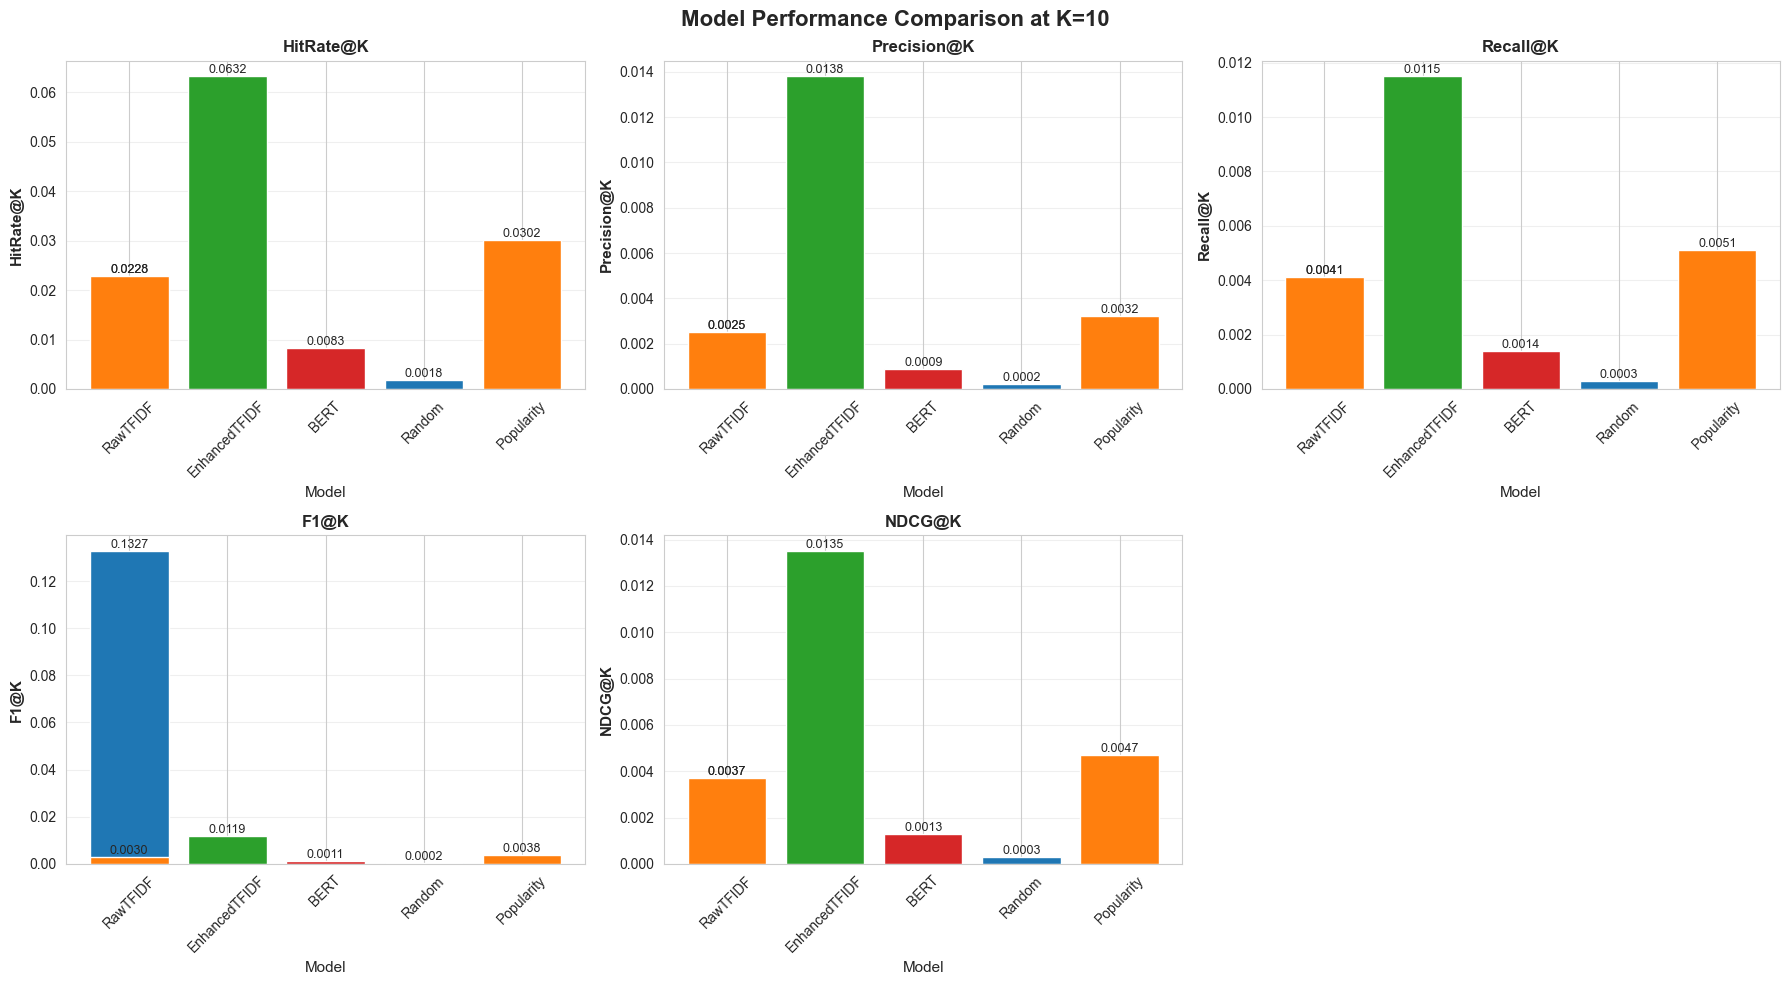

In [46]:
# Filter results for K=10
results_k10 = results_df[results_df['K'] == 10].copy()
#
# Create subplot for all metrics
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Model Performance Comparison at K=10', fontsize=16, fontweight='bold')
#
metrics_to_plot = ['HitRate@K', 'Precision@K', 'Recall@K', 'NDCG@K']
#
for idx, metric in enumerate(metrics_to_plot):
    row = idx // 3
    col = idx % 3
    ax = axes[row, col]
    
    # Create bar plot
    bars = ax.bar(results_k10['Model'], results_k10[metric], 
                   color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728'][:len(results_k10)])
    
    # Add value labels on top of bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.4f}',
                ha='center', va='bottom', fontsize=9)
    
    ax.set_ylabel(metric, fontsize=11, fontweight='bold')
    ax.set_xlabel('Model', fontsize=11)
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)
    ax.grid(axis='y', alpha=0.3)
#
# Remove the extra subplot
fig.delaxes(axes[1, 2])
#
plt.tight_layout()
plt.savefig('resultsComparison/metrics_comparison_k10.png', dpi=300, bbox_inches='tight')
plt.show()
#

### 12.2 Performance Across Different K Values

Line plots showing how metrics change with K

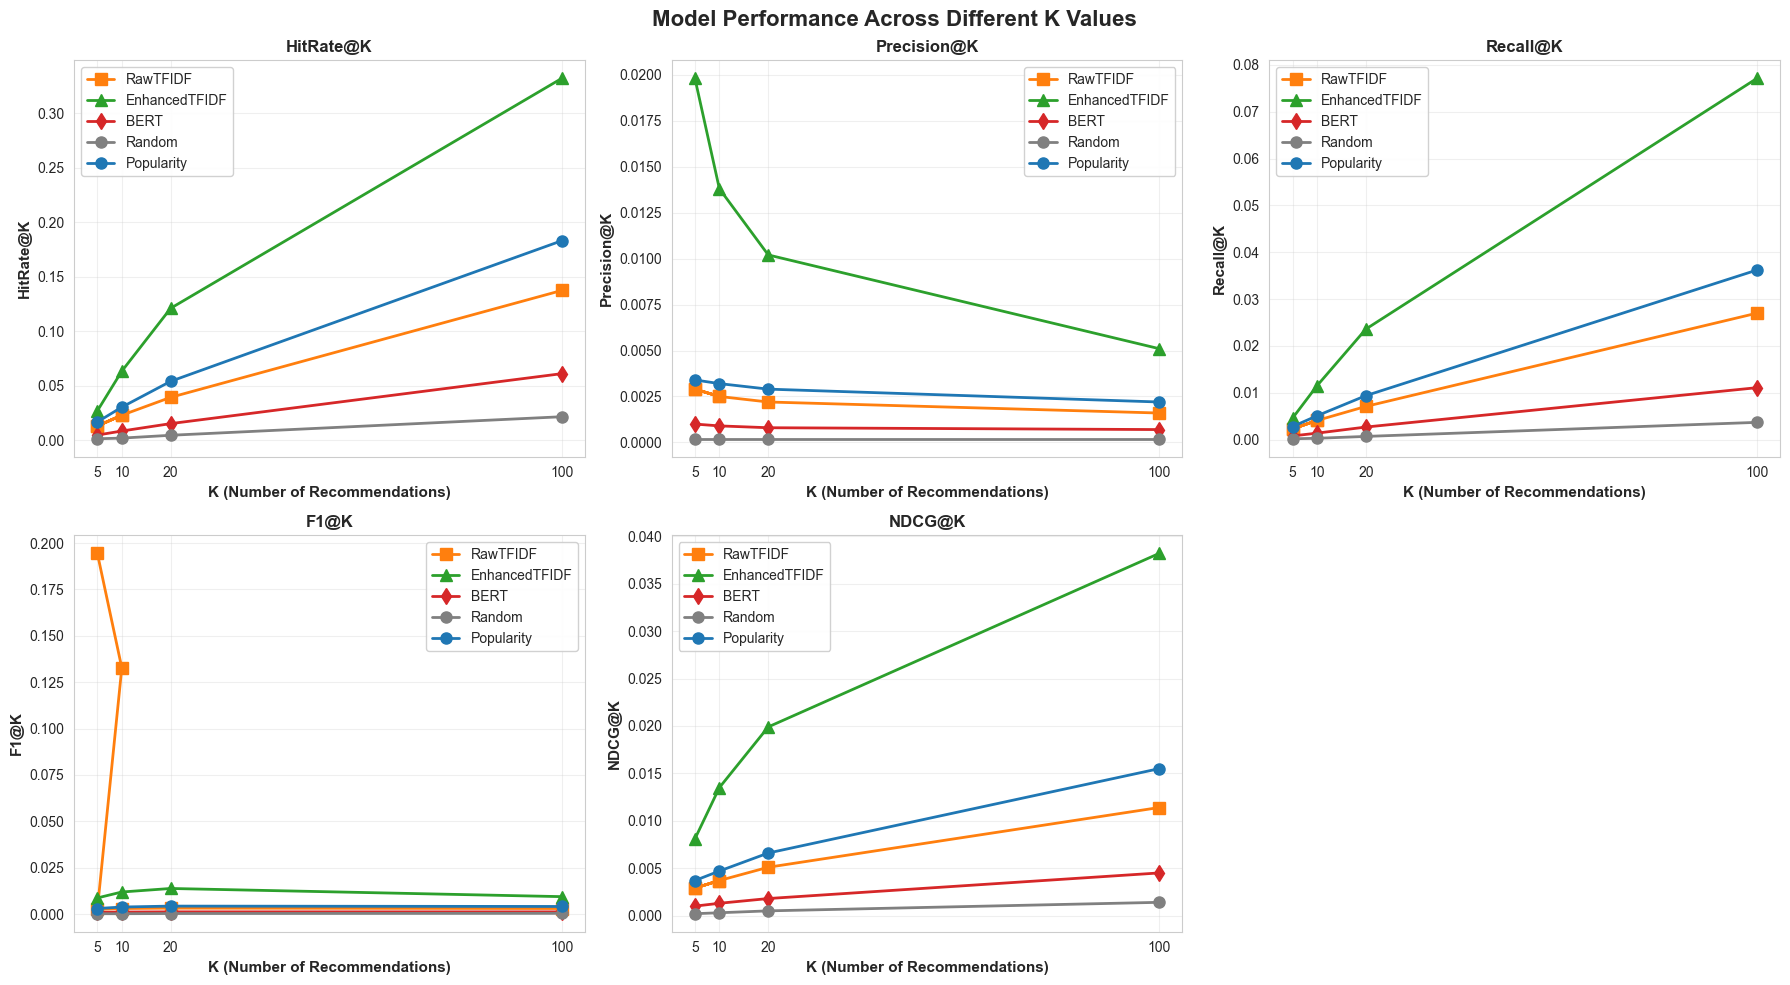

In [47]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle('Model Performance Across Different K Values', fontsize=16, fontweight='bold')
#
metrics_to_plot = ['HitRate@K', 'Precision@K', 'Recall@K', 'NDCG@K']
colors = {'Popularity': '#1f77b4', 'RawTFIDF': '#ff7f0e', 
          'EnhancedTFIDF': '#2ca02c', 'BERT': '#d62728'}
markers = {'Popularity': 'o', 'RawTFIDF': 's', 'EnhancedTFIDF': '^', 'BERT': 'd'}
#
for idx, metric in enumerate(metrics_to_plot):
    row = idx // 3
    col = idx % 3
    ax = axes[row, col]
    
    for model in results_df['Model'].unique():
        model_data = results_df[results_df['Model'] == model]
        ax.plot(model_data['K'], model_data[metric], 
                marker=markers.get(model, 'o'), 
                linewidth=2, markersize=8,
                label=model, color=colors.get(model, 'gray'))
    
    ax.set_xlabel('K (Number of Recommendations)', fontsize=11, fontweight='bold')
    ax.set_ylabel(metric, fontsize=11, fontweight='bold')
    ax.set_title(metric, fontsize=12, fontweight='bold')
    ax.legend(loc='best', framealpha=0.9)
    ax.grid(True, alpha=0.3)
    ax.set_xticks(TOP_K_VALUES)
#
# Remove the extra subplot
fig.delaxes(axes[1, 2])
#
plt.tight_layout()
plt.savefig('resultsComparison/metrics_across_k.png', dpi=300, bbox_inches='tight')
plt.show()
#

### 12.3 Relative Improvement Heatmap

Heatmap showing percentage improvement over popularity baseline

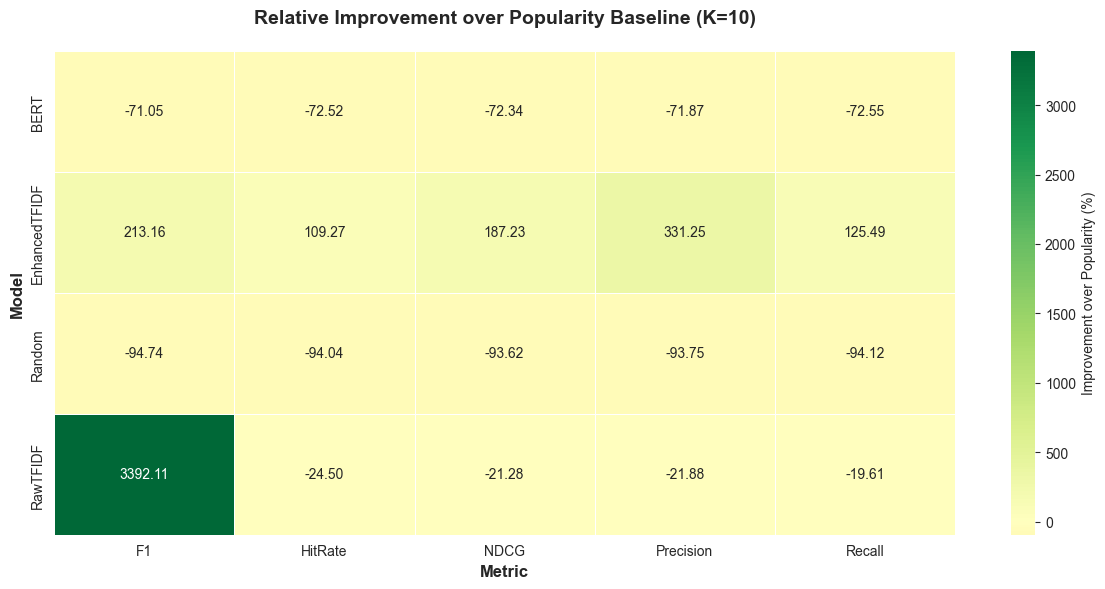

In [48]:
# Calculate relative improvements for all models and K values
improvement_data = []
#
for k in TOP_K_VALUES:
    pop_metrics = results_df[(results_df['Model'] == 'Popularity') & (results_df['K'] == k)]
    
    for model in models_to_compare:
        model_metrics = results_df[(results_df['Model'] == model) & (results_df['K'] == k)]
        
        if not pop_metrics.empty and not model_metrics.empty:
            for metric in ['HitRate@K', 'Precision@K', 'Recall@K', 'NDCG@K']:
                pop_val = pop_metrics[metric].values[0]
                model_val = model_metrics[metric].values[0]
                
                if pop_val > 0:
                    improvement = 100 * (model_val - pop_val) / pop_val
                else:
                    improvement = 0
                
                improvement_data.append({
                    'Model': model,
                    'K': k,
                    'Metric': metric.replace('@K', ''),
                    'Improvement (%)': improvement
                })
#
improvement_df = pd.DataFrame(improvement_data)
#
# Create heatmap for K=10
improvement_k10 = improvement_df[improvement_df['K'] == 10]
heatmap_data = improvement_k10.pivot(index='Model', columns='Metric', values='Improvement (%)')
#
plt.figure(figsize=(12, 6))
sns.heatmap(heatmap_data, annot=True, fmt='.2f', cmap='RdYlGn', center=0, 
            cbar_kws={'label': 'Improvement over Popularity (%)'}, linewidths=0.5)
plt.title('Relative Improvement over Popularity Baseline (K=10)', fontsize=14, fontweight='bold', pad=20)
plt.xlabel('Metric', fontsize=12, fontweight='bold')
plt.ylabel('Model', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('resultsComparison/improvement_heatmap_k10.png', dpi=300, bbox_inches='tight')
plt.show()
#

### 12.4 Fallback Usage Visualization

Bar chart showing primary vs fallback algorithm usage

In [55]:
import pandas as pd

# 1. Robust Helper Function (Checks for both attribute styles)
def get_fallback_stats(model_name, engine):
    primary = 0
    fallback = 0

    # Style A: New RecEngine (call_stats_ dict)
    if hasattr(engine, 'call_stats_'):
        s = engine.call_stats_
        primary = s.get('primary', 0)
        fallback = s.get('fallback', 0)

    # Style B: Original RecEngine (fallback_count attribute)
    elif hasattr(engine, 'fallback_count'):
        total = getattr(engine, 'total_count', 0)
        fallback = engine.fallback_count
        primary = max(0, total - fallback)

    # Calculate Percentage
    total = primary + fallback
    pct = (fallback / total * 100) if total > 0 else 0.0

    return {
        'Model': model_name,
        'primary': primary,
        'fallback': fallback,
        'fallback_pct': pct
    }

# 2. Collect stats from all available engines
fallback_data = []

# Check globals for engines and collect stats
if 'raw_engine' in globals():
    fallback_data.append(get_fallback_stats('Raw TF-IDF', raw_engine))

if 'enh_engine' in globals():
    fallback_data.append(get_fallback_stats('Enhanced TF-IDF', enh_engine))

if 'bert_engine' in globals():
    fallback_data.append(get_fallback_stats('BERT', bert_engine))

# 3. Create the DataFrame safely
if fallback_data:
    fallback_summary = pd.DataFrame(fallback_data)
    print("✅ fallback_summary created successfully:")
    print(fallback_summary)
else:
    # Create empty DF with correct columns to prevent plotting errors
    print("⚠️ No engines found. Creating empty summary.")
    fallback_summary = pd.DataFrame(columns=['Model', 'primary', 'fallback', 'fallback_pct'])

✅ fallback_summary created successfully:
             Model  primary  fallback  fallback_pct
0       Raw TF-IDF        0         0           0.0
1  Enhanced TF-IDF        0         0           0.0
2             BERT        0         0           0.0


✅ Stats Updated:
             Model  primary  fallback  fallback_pct
0       Raw TF-IDF        0         0           0.0
1  Enhanced TF-IDF        0         0           0.0
2             BERT        0         0           0.0


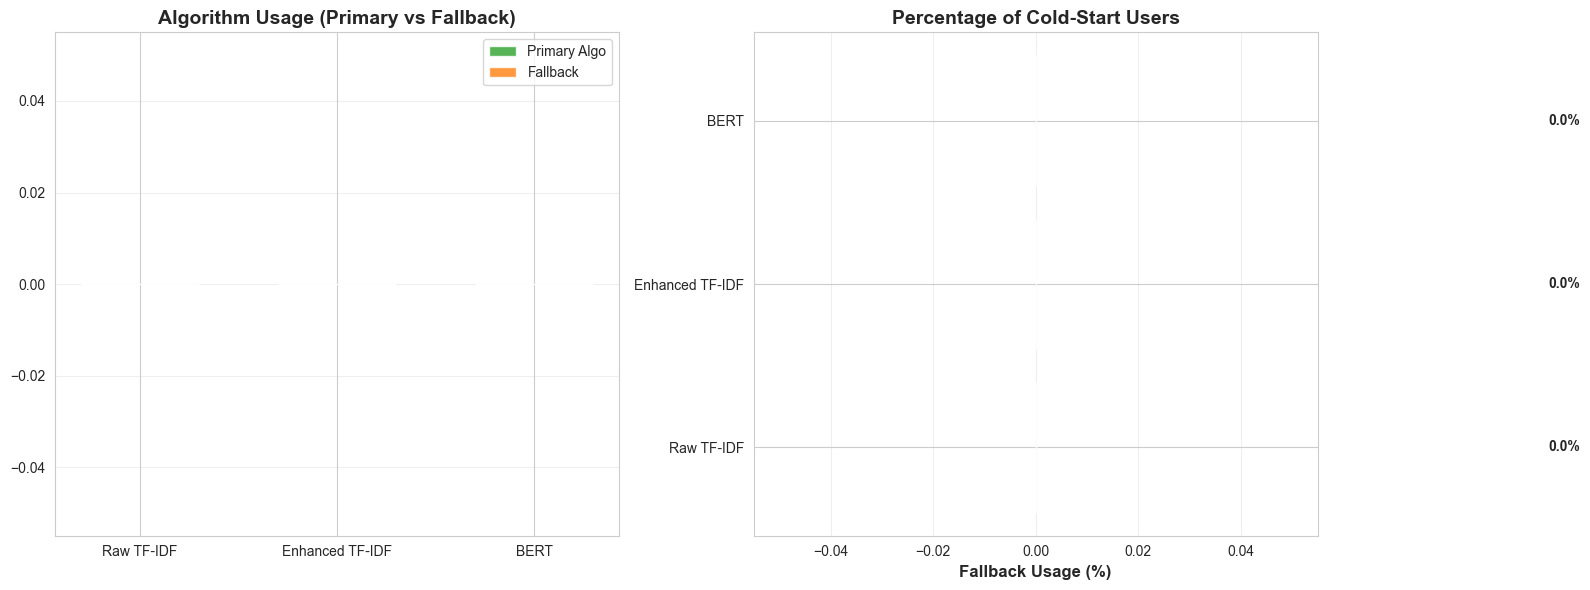

In [59]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Extract Fresh Stats from Engines ---
def get_fallback_stats(model_name, engine):
    primary, fallback = 0, 0

    # Handle both new and old engine versions
    if hasattr(engine, 'call_stats_'):
        s = engine.call_stats_
        primary = s.get('primary', 0)
        fallback = s.get('fallback', 0)
    elif hasattr(engine, 'fallback_count'):
        total = getattr(engine, 'total_count', 0)
        fallback = engine.fallback_count
        primary = max(0, total - fallback)

    total = primary + fallback
    pct = (fallback / total * 100) if total > 0 else 0.0

    return {
        'Model': model_name,
        'primary': primary,
        'fallback': fallback,
        'fallback_pct': pct
    }

fallback_data = []
# Only check for engines that actually exist in your kernel
if 'raw_engine' in globals(): fallback_data.append(get_fallback_stats('Raw TF-IDF', raw_engine))
if 'enh_engine' in globals(): fallback_data.append(get_fallback_stats('Enhanced TF-IDF', enh_engine))
if 'bert_engine' in globals(): fallback_data.append(get_fallback_stats('BERT', bert_engine))

if not fallback_data:
    print("⚠️ No engines found! Make sure you ran the training/eval cells.")
    fallback_summary = pd.DataFrame(columns=['Model', 'primary', 'fallback', 'fallback_pct'])
else:
    fallback_summary = pd.DataFrame(fallback_data)
    print("✅ Stats Updated:")
    print(fallback_summary)

# --- 2. Plotting ---
if not fallback_summary.empty:
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

    # A. Stacked Bar Chart (Counts)
    models = fallback_summary['Model'].tolist()
    primary_counts = fallback_summary['primary'].tolist()
    fallback_counts = fallback_summary['fallback'].tolist()
    x = np.arange(len(models))
    width = 0.6

    ax1.bar(x, primary_counts, width, label='Primary Algo', color='#2ca02c', alpha=0.8)
    ax1.bar(x, fallback_counts, width, bottom=primary_counts, label='Fallback', color='#ff7f0e', alpha=0.8)

    ax1.set_title('Algorithm Usage (Primary vs Fallback)', fontsize=14, fontweight='bold')
    ax1.set_xticks(x)
    ax1.set_xticklabels(models)
    ax1.legend()
    ax1.grid(axis='y', alpha=0.3)

    # Add count labels
    for i, (p, f) in enumerate(zip(primary_counts, fallback_counts)):
        total = p + f
        if total > 0:
            if p > 0: ax1.text(i, p/2, f"{p}", ha='center', color='white', fontweight='bold')
            if f > 0: ax1.text(i, p + f/2, f"{f}", ha='center', color='white', fontweight='bold')

    # B. Horizontal Bar Chart (Percentage)
    fallback_pcts = fallback_summary['fallback_pct'].tolist()
    bars = ax2.barh(models, fallback_pcts, color=['#ff7f0e', '#d62728', '#9467bd'][:len(models)], alpha=0.8)

    ax2.set_xlabel('Fallback Usage (%)', fontsize=12, fontweight='bold')
    ax2.set_title('Percentage of Cold-Start Users', fontsize=14, fontweight='bold')
    ax2.grid(axis='x', alpha=0.3)

    for i, (bar, pct) in enumerate(zip(bars, fallback_pcts)):
        ax2.text(pct + 0.1, i, f'{pct:.1f}%', va='center', fontweight='bold')

    plt.tight_layout()
    plt.show()

### 12.5 Radar Chart for Overall Model Comparison

Multi-dimensional comparison of all metrics at K=10

### 12.6 Summary Comparison Table

Combined visualization with key statistics

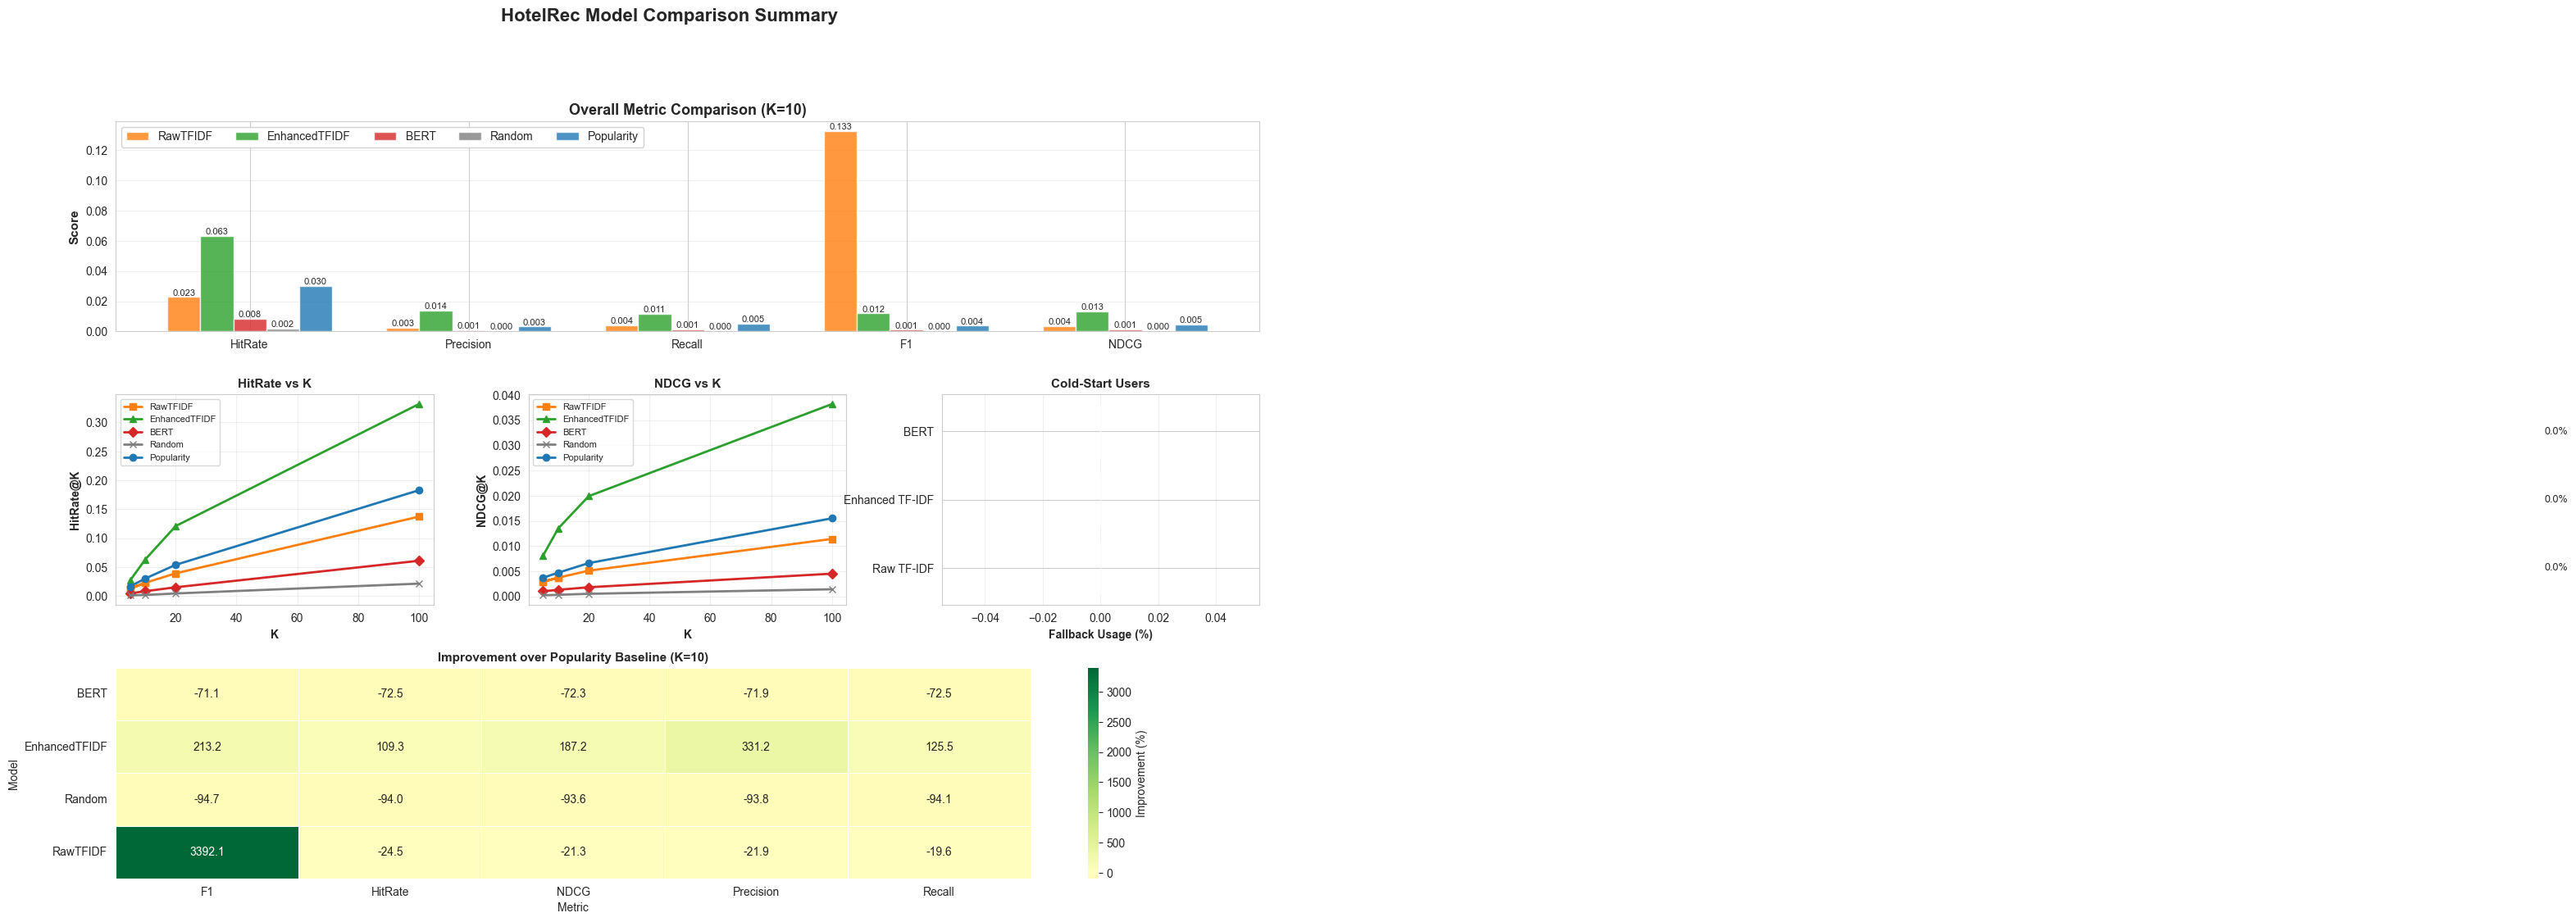

In [60]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. Prepare Data Subsets
results_k10 = results_df[results_df['K'] == 10].copy()

# 2. Define Plotting Variables
categories = ['HitRate', 'Precision', 'Recall', 'NDCG']
colors = {
    'Random': '#7f7f7f',
    'Popularity': '#1f77b4',
    'RawTFIDF': '#ff7f0e',
    'EnhancedTFIDF': '#2ca02c',
    'BERT': '#d62728'
}
markers = {
    'Random': 'x',
    'Popularity': 'o',
    'RawTFIDF': 's',
    'EnhancedTFIDF': '^',
    'BERT': 'D'
}

# 3. Calculate Improvement Data (for the Heatmap)
improvement_data = []
# Get baseline stats for K=10
pop_stats = results_k10[results_k10['Model'] == 'Popularity']

if not pop_stats.empty:
    for model in results_k10['Model'].unique():
        if model == 'Popularity': continue

        mod_stats = results_k10[results_k10['Model'] == model]
        if mod_stats.empty: continue

        for metric in ['HitRate@K', 'Precision@K', 'Recall@K', 'NDCG@K']:
            base = pop_stats[metric].values[0]
            val = mod_stats[metric].values[0]
            imp = (val - base) / base * 100 if base > 0 else 0

            improvement_data.append({
                'Model': model,
                'Metric': metric.replace('@K', ''),
                'Improvement (%)': imp
            })

improvement_k10 = pd.DataFrame(improvement_data)

# --- NOW RUN THE PLOTTING CODE ---

fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

# 1. Overall metric comparison
ax1 = fig.add_subplot(gs[0, :])
x_pos = np.arange(len(categories))
width = 0.15

for i, model in enumerate(results_k10['Model'].unique()):
    # Extract scores in the order of 'categories'
    # metrics correspond to: HitRate@K, Precision@K, Recall@K, F1@K, NDCG@K
    raw_metrics = ['HitRate@K', 'Precision@K', 'Recall@K', 'NDCG@K']
    model_scores = [results_k10[results_k10['Model'] == model][m].values[0] for m in raw_metrics]

    offset = width * (i - len(results_k10['Model'].unique())/2 + 0.5)
    bars = ax1.bar(x_pos + offset, model_scores, width,
                   label=model, color=colors.get(model, 'gray'), alpha=0.8)

    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.3f}', ha='center', va='bottom', fontsize=8)

ax1.set_ylabel('Score', fontsize=11, fontweight='bold')
ax1.set_title('Overall Metric Comparison (K=10)', fontsize=13, fontweight='bold')
ax1.set_xticks(x_pos)
ax1.set_xticklabels(categories)
ax1.legend(loc='upper left', ncol=5, framealpha=0.9)
ax1.grid(axis='y', alpha=0.3)

# 2. HitRate across K values
ax2 = fig.add_subplot(gs[1, 0])
for model in results_df['Model'].unique():
    model_data = results_df[results_df['Model'] == model]
    ax2.plot(model_data['K'], model_data['HitRate@K'],
            marker=markers.get(model, 'o'), linewidth=2, markersize=6,
            label=model, color=colors.get(model, 'gray'))
ax2.set_xlabel('K', fontsize=10, fontweight='bold')
ax2.set_ylabel('HitRate@K', fontsize=10, fontweight='bold')
ax2.set_title('HitRate vs K', fontsize=11, fontweight='bold')
ax2.legend(fontsize=8)
ax2.grid(True, alpha=0.3)

# 3. NDCG across K values
ax3 = fig.add_subplot(gs[1, 1])
for model in results_df['Model'].unique():
    model_data = results_df[results_df['Model'] == model]
    ax3.plot(model_data['K'], model_data['NDCG@K'],
            marker=markers.get(model, 'o'), linewidth=2, markersize=6,
            label=model, color=colors.get(model, 'gray'))
ax3.set_xlabel('K', fontsize=10, fontweight='bold')
ax3.set_ylabel('NDCG@K', fontsize=10, fontweight='bold')
ax3.set_title('NDCG vs K', fontsize=11, fontweight='bold')
ax3.legend(fontsize=8)
ax3.grid(True, alpha=0.3)

# 4. Fallback usage
ax4 = fig.add_subplot(gs[1, 2])
if 'fallback_summary' in globals() and not fallback_summary.empty:
    fallback_pcts = fallback_summary['fallback_pct'].tolist()
    models_list = fallback_summary['Model'].tolist()
    bars = ax4.barh(models_list, fallback_pcts,
                    color=[colors.get(m, 'gray') for m in models_list], alpha=0.8)
    for i, (bar, pct) in enumerate(zip(bars, fallback_pcts)):
        ax4.text(pct + 0.5, i, f'{pct:.1f}%', va='center', fontsize=9)
else:
    ax4.text(0.5, 0.5, "No Fallback Data", ha='center', va='center')

ax4.set_xlabel('Fallback Usage (%)', fontsize=10, fontweight='bold')
ax4.set_title('Cold-Start Users', fontsize=11, fontweight='bold')
ax4.grid(axis='x', alpha=0.3)

# 5. Improvement heatmap
ax5 = fig.add_subplot(gs[2, :])
if not improvement_k10.empty:
    pivot_imp = improvement_k10.pivot(index='Model', columns='Metric', values='Improvement (%)')
    sns.heatmap(pivot_imp, annot=True, fmt='.1f', cmap='RdYlGn', center=0,
                cbar_kws={'label': 'Improvement (%)'}, linewidths=0.5, ax=ax5)
ax5.set_title('Improvement over Popularity Baseline (K=10)', fontsize=11, fontweight='bold')

fig.suptitle('HotelRec Model Comparison Summary', fontsize=16, fontweight='bold', y=0.995)
plt.savefig('resultsComparison/comprehensive_summary.png', dpi=300, bbox_inches='tight')
plt.show()

In [54]:
# %%
import os
import joblib

os.makedirs("modelsNew", exist_ok=True)

# Save only the algo objects – smaller and easier to reload
joblib.dump(rand_algo, "modelsNew/random_algo.joblib")
joblib.dump(pop_algo, "modelsNew/popularity_algo.joblib")
joblib.dump(raw_algo, "modelsNew/raw_tfidf_algo.joblib")
joblib.dump(enh_algo, "modelsNew/enhanced_tfidf_algo.joblib")

if USE_BERT:
    # This may still be large; only save if you really need it.
    joblib.dump(bert_algo, "modelsNew/bert_content_algo.joblib")

# NEW: also persist the fitted TF‑IDF vectorizers explicitly
if getattr(raw_algo, "vectorizer_", None) is not None:
    joblib.dump(raw_algo.vectorizer_, "modelsNew/raw_tfidf_vectorizer.joblib")
    print("Saved raw TF‑IDF vectorizer to modelsNew/raw_tfidf_vectorizer.joblib")

if getattr(enh_algo, "vectorizer_", None) is not None:
    joblib.dump(enh_algo.vectorizer_, "modelsNew/enhanced_tfidf_vectorizer.joblib")
    print("Saved enhanced TF‑IDF vectorizer to modelsNew/enhanced_tfidf_vectorizer.joblib")

print("Saved trained algorithms into 'modelsNew/'")


Saved raw TF‑IDF vectorizer to modelsNew/raw_tfidf_vectorizer.joblib
Saved enhanced TF‑IDF vectorizer to modelsNew/enhanced_tfidf_vectorizer.joblib
Saved trained algorithms into 'modelsNew/'


In [ ]:
import os
import json
from collections import Counter
import numpy as np

# We only care about these K values and models for the export
EXPORT_K_VALUES = [10, 20, 50, 100]
EXPORT_MODELS = ["Random", "Popularity", "EnhancedTFIDF"]

def compute_coverage_gini(engine, test_dict, k=10, sample_size=None):
    """Compute catalog coverage and a Gini-like concentration index silently."""
    users = list(test_dict.keys())
    if sample_size is not None and sample_size < len(users):
        np.random.seed(42)
        users = np.random.choice(users, size=sample_size, replace=False).tolist()

    all_recommended = set()
    recommendation_counts = Counter()

    for u in users:
        recs = engine.recommend(user=u, n=k, filter_seen_items=True)
        if recs is not None and not recs.empty:
            items = recs["item"].astype(str).tolist()
            all_recommended.update(items)
            recommendation_counts.update(items)

    if hasattr(engine.algo, "items_") and engine.algo.items_ is not None:
        total_items = len(engine.algo.items_)
    else:
        total_items = len(all_recommended)

    coverage = len(all_recommended) / total_items if total_items else 0.0

    counts = sorted(recommendation_counts.values())
    n = len(counts)
    if n == 0:
        gini = 0.0
    else:
        counts_arr = np.array(counts, dtype=np.float64)
        cumsum = np.cumsum(counts_arr)
        gini = (2.0 * np.sum((np.arange(1, n + 1) * counts_arr))) / (n * cumsum[-1]) - (n + 1) / n

    return coverage, gini

# Build the nested export dictionary
metrics_export = {}

engine_by_model = {
    "Random": rand_engine,
    "Popularity": pop_engine,
    "EnhancedTFIDF": enh_engine,
}

for model in EXPORT_MODELS:
    model_rows = results_df[results_df["Model"] == model]
    if model_rows.empty:
        continue

    metrics_export[model] = {}
    for k in EXPORT_K_VALUES:
        row = model_rows[model_rows["K"] == k]
        if row.empty:
            continue

        rc = row.iloc[0]

        # ranking metrics
        metrics_k = {
            "hitrate": round(float(rc["HitRate@K"]), 4),
            "precision": round(float(rc["Precision@K"]), 4),
            "ndcg": round(float(rc["NDCG@K"]), 4),
        }

        # coverage / gini at this K
        cov, gini = compute_coverage_gini(
            engine_by_model[model],
            test_dict,
            k=k,
            sample_size=SAMPLE_USERS,
        )
        metrics_k["coverage"] = round(float(cov), 4)
        metrics_k["gini"] = round(float(gini), 4)

        metrics_export[model][str(k)] = metrics_k

# Optionally save to JSON so you can re-use / compare later
os.makedirs("resultsComparison", exist_ok=True)
export_path = os.path.join(
    "resultsComparison", "metrics_export_random_pop_enhanced.json"
)

with open(export_path, "w", encoding="utf-8") as f:
    json.dump(metrics_export, f, indent=2)

print(f"Saved metrics to {export_path}")
metrics_export
